
# PDAN8412/w Programming for Data Analytics 2
## Portfolio of Evidence 2026: Part 2
### Logistic Regression from Scratch

**Student:** Rohin Maharaj  
**Module:** Programming for Data Analytics 2  
**Assessment:** Portfolio of Evidence (POE), Part 2  
**Academic Year:** 2026

---

## Project Overview

This project investigates the implementation of logistic regression from scratch to classify books according to their observed New York Times (NYT) bestseller list membership. The study combines historical NYT bestseller records with book metadata from the Goodreads Book Graph to construct a binary classification dataset.

The analysis follows a structured data analytics workflow: dataset suitability assessment, exploratory data analysis (EDA), data quality investigation, feature selection, preprocessing, model implementation, training, evaluation and interpretation. PySpark is used for data analysis, while Python libraries support data preparation, visualisation and the evaluation of model performance.

The logistic regression algorithm is implemented from scratch using NumPy, including probability estimation, binary cross entropy loss and gradient descent. Model development includes training and validation, investigation of appropriate classification thresholds, and comparison of baseline and extended training experiments.

The study also considers class imbalance, potential data leakage, limitations in matching records across datasets, and the distinction between observed bestseller list membership and general commercial success. Conclusions are based on the results obtained and the limitations of the available data.



## 1. Problem Statement

### 1.1 Problem Statement

Bestseller lists provide a record of books that achieved a recognised level of commercial visibility. Analysing historical bestseller records may help identify patterns and characteristics associated with bestseller list membership.

The challenge is to develop a binary classification model that estimates whether a book belongs to the bestseller category using appropriate input features. Logistic regression will be implemented from scratch to demonstrate the application of a statistical learning algorithm to this classification problem.

A key consideration is that the available dataset primarily contains bestseller list entries. Suitable non bestseller examples must therefore be identified or obtained before a valid binary classification model can be trained.

For this study, the positive class represents books identified as having appeared on the selected NYT bestseller lists, while the comparison class consists of Goodreads records that did not match the selected NYT records under the matching procedure. A non-match does not prove that a book was never a bestseller, because differences in edition identifiers, dataset coverage and publication records may affect matching. The model therefore estimates membership in the constructed dataset's observed bestseller class rather than definitive bestseller status across the entire book market.


## 2. Project Aim and Objectives

### 2.1 Project Aim

The aim of this project is to implement, train and evaluate a logistic regression classifier from scratch to investigate the prediction of bestseller list membership using book related data.

### 2.2 Project Objectives

The objectives are to:

1. Identify and justify a suitable dataset for the binary classification task.
2. Conduct exploratory data analysis using Python and PySpark where appropriate.
3. Investigate data quality, missing values, repeated records and feature suitability.
4. Establish a defensible binary target variable and prepare appropriate predictor features.
5. Implement logistic regression from scratch using NumPy, including probability estimation, the loss function and gradient descent.
6. Train the model using an appropriate training and validation strategy.
7. Evaluate the model using suitable classification metrics and visualisations.
8. Investigate justified model improvements and compare their results.
9. Interpret the findings, acknowledge limitations and document the process using appropriate academic referencing.



## 3. Scope and Methodological Approach

The project will follow a structured data analytics workflow, beginning with dataset investigation and suitability assessment before proceeding to exploratory analysis, preprocessing, model development and evaluation.

Python will be used for data manipulation, visualisation and model implementation. PySpark will be used for data analysis where appropriate, in accordance with the POE requirements. The logistic regression algorithm itself will be implemented from scratch using NumPy rather than relying on a prebuilt logistic regression estimator for the primary model.

The dataset, target variable and predictor features will be finalised only after investigating data quality, available records and the feasibility of identifying both classes. Data leakage will be considered when selecting predictors, particularly variables that reveal a book's subsequent bestseller list performance.

The model will be evaluated using metrics appropriate to the class distribution and classification objective. Conclusions will be based on the actual results obtained during the analysis.

The project will document the rationale for methodological decisions, interpret findings at each stage and acknowledge data limitations.


# 4. Dataset Selection and Suitability Assessment

## 4.1 Dataset Source and Description

The initial dataset selected for investigation is `nyt-bestsellers.csv`, which contains historical entries from New York Times (NYT) bestseller lists. The dataset includes publication dates, list categories, rankings, ISBN identifiers, titles, authors, descriptions, prices and the number of weeks books appeared on a list.

The dataset is relevant to the classification problem because it provides observed evidence of bestseller list membership. However, the records primarily describe books that appeared on the selected lists. The dataset therefore provides evidence for identifying the positive class but does not independently establish a representative or verified negative class.

## 4.2 Initial Dataset Characteristics

The validated dataset contains 61,430 records and 12 original columns. Initial investigation identified 59 distinct list categories and 6,577 distinct titles. These characteristics provide a substantial historical collection for investigating patterns associated with bestseller list membership.

The number of records must not be interpreted as the number of unique books. A title or ISBN may appear repeatedly because a book was listed on different dates or in different categories. Missing identifiers and repeated records must therefore be investigated before the modelling population is constructed.

## 4.3 Dataset Suitability and Quality Requirements

The dataset is assessed against five requirements:

1. **Sufficient data:** The source must provide enough usable records to meet the POE requirement of at least 10,000 records.
2. **Target validity:** The target variable must be supported by a defensible definition of observed bestseller list membership.
3. **Predictor suitability:** Selected features should be relevant to the intended prediction task and should not reveal the outcome being predicted.
4. **Data quality:** Missing values, identifier validity, repeated records, date parsing and inconsistent representations must be investigated.
5. **Class construction:** The analysis must distinguish books observed on the selected bestseller lists from books that were simply not matched to those records.

The initial NYT dataset is suitable for identifying observed list membership, but it is insufficient on its own for a two-class classification task. A second source of book metadata is therefore investigated later in the project to construct a comparison class. The limitations of matching records across sources must be considered when interpreting the resulting model.

## 4.4 Assessment Approach

The investigation begins by validating the dataset's structure, record count, publication dates, identifier completeness and repeated records. Exploratory analysis then examines list categories, ranking patterns and weeks on the list. The findings are used to guide dataset construction, target definition, feature selection and preprocessing before model training begins.


In [6]:
# Part 2: Environment Verification

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import pyspark

print("=" * 50)
print("PDAN8412 POE 2026: PART 2")
print("Environment Verification")
print("=" * 50)

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("PySpark version:", pyspark.__version__)

print("\nEnvironment check completed successfully.")


PDAN8412 POE 2026: PART 2
Environment Verification
Python version: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\rohin\anaconda3\envs\pdan8412\python.exe
NumPy version: 2.5.3
Pandas version: 2.2.3
Scikit-learn version: 1.9.1
PySpark version: 4.2.0

Environment check completed successfully.


## 4.5 Dataset Structure and Book Identifier Analysis

The initial suitability assessment identified the need to validate the dataset's structure before relying on its summary statistics. The following analysis uses PySpark to inspect the schema, record count, publication date coverage, list category distribution and repeated ISBN-13 identifiers and titles.

These checks help distinguish the number of list entries from the number of distinct books and identify data quality issues that could affect later matching and modelling. The initial Spark load is also checked against a Pandas read of the same CSV file to verify that quoted fields and multiline descriptions have been parsed correctly.


In [7]:

# Analyse dataset structure and book identifiers

from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Initialise the Spark session
spark = (
    SparkSession.builder
    .appName("PDAN8412_Part2_Dataset_Investigation")
    .getOrCreate()
)

# Load the original CSV into Spark
data_path = Path("../Data/Raw/nyt-bestsellers.csv").resolve()

spark_books = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(data_path))
)

# Display the schema
print("Dataset schema:")
spark_books.printSchema()

# Confirm the record and column counts
print("\nDataset dimensions")
print("Records:", spark_books.count())
print("Columns:", len(spark_books.columns))

# Examine the date range
print("\nPublication date coverage:")
spark_books.select(
    F.min("published_date").alias("Earliest_Date"),
    F.max("published_date").alias("Latest_Date"),
    F.countDistinct("published_date").alias("Distinct_Dates")
).show(truncate=False)

# Examine the distribution of list categories
print("\nMost frequent list categories:")
(
    spark_books.groupBy("list_name")
    .agg(F.count("*").alias("Record_Count"))
    .orderBy(F.desc("Record_Count"))
    .show(15, truncate=False)
)

# Investigate repeated ISBN-13 identifiers
print("\nISBN-13 identifier analysis:")

isbn13_summary = spark_books.agg(
    F.count("*").alias("Total_Records"),
    F.count("isbn13").alias("Non_Missing_ISBN13"),
    F.countDistinct("isbn13").alias("Distinct_ISBN13")
)

isbn13_summary.show(truncate=False)

repeated_isbn13 = (
    spark_books
    .filter(F.col("isbn13").isNotNull())
    .groupBy("isbn13")
    .agg(
        F.count("*").alias("Occurrences"),
        F.countDistinct("title").alias("Distinct_Titles"),
        F.countDistinct("list_name").alias("Distinct_Lists")
    )
    .filter(F.col("Occurrences") > 1)
    .orderBy(F.desc("Occurrences"))
)

print("Number of ISBN-13 identifiers appearing more than once:",
      repeated_isbn13.count())

print("\nExamples of repeated ISBN-13 identifiers:")
repeated_isbn13.show(10, truncate=False)

# Investigate titles that appear more than once
repeated_titles = (
    spark_books
    .groupBy("title")
    .agg(
        F.count("*").alias("Occurrences"),
        F.countDistinct("isbn13").alias("Distinct_ISBN13")
    )
    .filter(F.col("Occurrences") > 1)
    .orderBy(F.desc("Occurrences"))
)

print("Number of titles appearing more than once:",
      repeated_titles.count())

print("\nExamples of repeated titles:")
repeated_titles.show(10, truncate=False)


Dataset schema:
root
 |-- published_date: string (nullable = true)
 |-- list_name: string (nullable = true)
 |-- list_name_encoded: string (nullable = true)
 |-- rank: string (nullable = true)
 |-- isbn13: string (nullable = true)
 |-- isbn10: string (nullable = true)
 |-- title: string (nullable = true)
 |-- author: string (nullable = true)
 |-- description: string (nullable = true)
 |-- amazon_product_url: string (nullable = true)
 |-- price: string (nullable = true)
 |-- weeks_on_list: string (nullable = true)


Dataset dimensions
Records: 61723
Columns: 12

Publication date coverage:
+-------------+-----------+--------------+
|Earliest_Date|Latest_Date|Distinct_Dates|
+-------------+-----------+--------------+
|\t2"         | "         |579           |
+-------------+-----------+--------------+


Most frequent list categories:
+------------------------------------+------------+
|list_name                           |Record_Count|
+------------------------------------+------------+
|


### 4.6 Initial Findings and Data Quality Concerns

The initial Spark analysis identified frequent repetition of ISBN-13 identifiers and book titles. Of the 61,723 records reported by Spark, 61,459 contained a non-missing ISBN-13 value, representing 8,935 distinct ISBN-13 identifiers. A total of 5,689 ISBN-13 identifiers appeared in more than one record.

The analysis also identified 4,393 titles appearing in multiple records. These repetitions may reflect books appearing on different weekly bestseller lists, books appearing in multiple list categories, or different editions sharing a title. Therefore, repeated records cannot automatically be treated as erroneous duplicates.

Two data quality concerns require further investigation. First, the Spark record count differs from the earlier Pandas record count of 61,430. Second, the publication date summary did not return a clearly interpretable earliest and latest date. These discrepancies must be resolved before finalising the dataset or making decisions about preprocessing.

The next step is to validate CSV parsing, reconcile the record counts and inspect the publication date values.


In [8]:

# 4.7 Validate CSV Parsing and Publication Dates

from pathlib import Path
import pandas as pd
from pyspark.sql import functions as F

data_path = Path("../Data/Raw/nyt-bestsellers.csv").resolve()

# Compare Pandas and Spark record counts using the same file
pandas_check = pd.read_csv(data_path)

print("Pandas record count:", len(pandas_check))
print("Spark record count, current load:", spark_books.count())

# Reload the CSV with multiline records enabled
spark_books_multiline = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("multiLine", True)
    .option("quote", '"')
    .option("escape", '"')
    .csv(str(data_path))
)

print(
    "Spark record count, multiline load:",
    spark_books_multiline.count()
)

# Inspect publication date values from both loading methods
print("\nPandas publication date examples:")
display(
    pandas_check["published_date"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nSpark publication date examples, current load:")
spark_books.select("published_date").show(10, truncate=False)

print("\nSpark publication date examples, multiline load:")
spark_books_multiline.select("published_date").show(10, truncate=False)

# Parse publication dates in the multiline-loaded Spark DataFrame
spark_books_multiline = spark_books_multiline.withColumn(
    "published_date_parsed",
    F.to_date(F.trim(F.col("published_date")), "yyyy-MM-dd")
)

print("\nPublication date parsing summary:")
spark_books_multiline.select(
    F.count("*").alias("Total_Records"),
    F.count("published_date_parsed").alias("Valid_Dates"),
    F.sum(
        F.when(
            F.col("published_date_parsed").isNull(),
            1
        ).otherwise(0)
    ).alias("Invalid_or_Missing_Dates"),
    F.min("published_date_parsed").alias("Earliest_Date"),
    F.max("published_date_parsed").alias("Latest_Date"),
    F.countDistinct("published_date_parsed").alias("Distinct_Dates")
).show(truncate=False)

# Display dates that could not be parsed
print("\nExamples of invalid publication dates:")
(
    spark_books_multiline
    .filter(F.col("published_date_parsed").isNull())
    .select("published_date")
    .distinct()
    .show(20, truncate=False)
)


Pandas record count: 61430
Spark record count, current load: 61723
Spark record count, multiline load: 61430

Pandas publication date examples:


published_date
2015-11-15    215
2016-01-31    215
2015-12-13    215
2016-01-03    215
2016-01-10    215
2015-12-20    215
2015-12-27    215
2015-12-06    215
2015-11-29    215
2015-11-22    215
Name: count, dtype: int64


Spark publication date examples, current load:
+--------------+
|published_date|
+--------------+
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
+--------------+
only showing top 10 rows

Spark publication date examples, multiline load:
+--------------+
|published_date|
+--------------+
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
|2010-01-03    |
+--------------+
only showing top 10 rows

Publication date parsing summary:
+-------------+-----------+------------------------+-------------+-----------+--------------+
|Total_Records|Valid_Dates|Invalid_or_Missing_Dates|Earliest_Date|Latest_Date|Distinct_Dates|
+-------------+-----------+------------------------+-------------+-----------+--------------+
|61430        |61430      |0                       |2010-01


### 4.8 CSV Parsing Validation and Publication Date Coverage

The initial Spark load returned 61,723 records, which differed from the 61,430 records reported by Pandas. The CSV was therefore reloaded using Spark's multiline parsing option. This second load returned 61,430 records, matching the Pandas result.

This discrepancy demonstrates the importance of validating data ingestion before conducting further analysis. The multiline-loaded Spark DataFrame will be used for subsequent investigations, subject to further data quality checks.

The publication date validation identified 522 distinct dates between 3 January 2010 and 29 December 2019. All 61,430 records had valid publication dates, with no invalid or missing dates identified by the date parsing check.

The date coverage is now established for the loaded dataset. Further checks are still required to confirm that the remaining columns have been parsed consistently and that missing values are represented correctly.


In [9]:

# 4.9 Validate Column Completeness and Data Types

from pyspark.sql import functions as F
import pandas as pd

# Confirm the validated Spark DataFrame dimensions
print("Validated Spark record count:", spark_books_multiline.count())
print("Validated Spark column count:", len(spark_books_multiline.columns))

# Compare column names
print("\nPandas columns:")
print(pandas_check.columns.tolist())

print("\nSpark columns:")
print(spark_books_multiline.columns)

# Compare missing values in Pandas and Spark
pandas_missing = pandas_check.isna().sum()

spark_missing_expressions = [
    F.sum(
        F.when(
            F.col(column).isNull() |
            (F.trim(F.col(column)) == ""),
            1
        ).otherwise(0)
    ).alias(column)
    for column in spark_books_multiline.columns
]

spark_missing_row = (
    spark_books_multiline
    .select(*spark_missing_expressions)
    .first()
    .asDict()
)

missing_comparison = pd.DataFrame({
    "Pandas_Missing": pandas_missing,
    "Spark_Missing": pd.Series(spark_missing_row)
})

missing_comparison["Difference"] = (
    missing_comparison["Spark_Missing"]
    - missing_comparison["Pandas_Missing"]
)

print("\nMissing-value comparison:")
display(missing_comparison)

# Check exact duplicate rows in the validated Spark DataFrame
print("\nExact duplicate row analysis:")

distinct_row_count = spark_books_multiline.distinct().count()
total_row_count = spark_books_multiline.count()

print("Total records:", total_row_count)
print("Distinct complete rows:", distinct_row_count)
print("Exact duplicate rows:", total_row_count - distinct_row_count)

# Display the validated schema
print("\nValidated Spark schema:")
spark_books_multiline.printSchema()


Validated Spark record count: 61430
Validated Spark column count: 13

Pandas columns:
['published_date', 'list_name', 'list_name_encoded', 'rank', 'isbn13', 'isbn10', 'title', 'author', 'description', 'amazon_product_url', 'price', 'weeks_on_list']

Spark columns:
['published_date', 'list_name', 'list_name_encoded', 'rank', 'isbn13', 'isbn10', 'title', 'author', 'description', 'amazon_product_url', 'price', 'weeks_on_list', 'published_date_parsed']

Missing-value comparison:


,Pandas_Missing,Spark_Missing,Difference
amazon_product_url,0.0,0,0.0
author,69.0,69,0.0
description,8119.0,8119,0.0
isbn10,3453.0,1284,-2169.0
isbn13,4.0,4,0.0
list_name,0.0,0,0.0
list_name_encoded,0.0,0,0.0
price,0.0,0,0.0
published_date,0.0,0,0.0
published_date_parsed,NaN,0,NaN



Exact duplicate row analysis:
Total records: 61430
Distinct complete rows: 61430
Exact duplicate rows: 0

Validated Spark schema:
root
 |-- published_date: string (nullable = true)
 |-- list_name: string (nullable = true)
 |-- list_name_encoded: string (nullable = true)
 |-- rank: string (nullable = true)
 |-- isbn13: string (nullable = true)
 |-- isbn10: string (nullable = true)
 |-- title: string (nullable = true)
 |-- author: string (nullable = true)
 |-- description: string (nullable = true)
 |-- amazon_product_url: string (nullable = true)
 |-- price: string (nullable = true)
 |-- weeks_on_list: string (nullable = true)
 |-- published_date_parsed: date (nullable = true)




### 4.10 Data Completeness and Duplicate Validation

The validated multiline Spark DataFrame contains 61,430 records, matching the Pandas record count. The dataset contains 12 original columns, with an additional parsed publication date column created during validation.

The duplicate analysis identified 61,430 distinct complete rows, indicating that no exact duplicate rows were found in the validated Spark DataFrame. However, this does not mean that every row represents a unique book, as repeated ISBNs and titles were identified in the earlier analysis.

The missing-value comparison showed agreement between Pandas and Spark for the author, description and ISBN-13 columns. However, the tools reported different missing-value counts for ISBN-10: Pandas identified 3,453 missing values, while Spark identified 1,284 null or blank values. This discrepancy requires further investigation before the missing-value profile can be finalised.

The validated publication date column contains 61,430 successfully parsed dates, with no invalid or missing dates. The dataset is therefore suitable for further investigation, subject to resolving the ISBN-10 discrepancy and assessing the availability of reliable non-bestseller examples.


In [10]:

# 4.11 Investigating ISBN-10 Missing Values

from pyspark.sql import functions as F
import pandas as pd

# Examine ISBN-10 values in Pandas
print("Pandas ISBN-10 missing values:")
print(pandas_check["isbn10"].isna().sum())

print("\nPandas ISBN-10 value types:")
print(
    pandas_check["isbn10"]
    .map(lambda value: type(value).__name__)
    .value_counts(dropna=False)
)

print("\nPandas ISBN-10 sample values, including missing values:")
print(
    pandas_check["isbn10"]
    .astype("string")
    .value_counts(dropna=False)
    .head(15)
)

# Examine raw ISBN-10 values in the validated Spark DataFrame
print("\nSpark ISBN-10 null count:")
spark_books_multiline.select(
    F.sum(
        F.when(F.col("isbn10").isNull(), 1).otherwise(0)
    ).alias("Null_Count")
).show()

print("\nSpark ISBN-10 values that may represent missing data:")
(
    spark_books_multiline
    .groupBy("isbn10")
    .count()
    .filter(
        F.col("isbn10").isNull()
        | (F.trim(F.col("isbn10")) == "")
        | F.lower(F.trim(F.col("isbn10"))).isin(
            "nan", "null", "none", "na", "n/a"
        )
    )
    .orderBy(F.desc("count"))
    .show(20, truncate=False)
)

# Compare distinct ISBN-10 representations
print("\nDistinct non-null ISBN-10 values in Spark:")
print(
    spark_books_multiline
    .filter(F.col("isbn10").isNotNull())
    .select("isbn10")
    .distinct()
    .count()
)

# Inspect representative rows with missing ISBN-10 in Pandas
print("\nExamples of rows with missing ISBN-10 in Pandas:")
display(
    pandas_check.loc[
        pandas_check["isbn10"].isna(),
        ["published_date", "title", "author", "isbn13", "isbn10"]
    ].head(10)
)


Pandas ISBN-10 missing values:
3453

Pandas ISBN-10 value types:
isbn10
str      57977
float     3453
Name: count, dtype: int64

Pandas ISBN-10 sample values, including missing values:
isbn10
<NA>          3453
0316017930     374
0375869026     365
0143125478     339
0849946158     268
1400064163     267
0375842209     264
0761148574     261
0802473156     233
080241270X     231
0805095152     229
0679603751     222
1400052181     218
0374533555     208
0399255370     208
Name: count, dtype: Int64

Spark ISBN-10 null count:
+----------+
|Null_Count|
+----------+
|      1284|
+----------+


Spark ISBN-10 values that may represent missing data:
+------+-----+
|isbn10|count|
+------+-----+
|None  |2169 |
|NULL  |1284 |
+------+-----+


Distinct non-null ISBN-10 values in Spark:
8124

Examples of rows with missing ISBN-10 in Pandas:


,published_date,title,author,isbn13,isbn10
4091,2011-02-13,HEAVEN IS FOR REAL,Todd Burpo with Lynn Vincent,9780849949203,NaN
4092,2011-02-13,BATTLE HYMN OF THE TIGER MOTHER,Amy Chua,9781101475454,NaN
4191,2011-02-20,HEAVEN IS FOR REAL,Todd Burpo with Lynn Vincent,9780849949203,NaN
4193,2011-02-20,BATTLE HYMN OF THE TIGER MOTHER,Amy Chua,9781101475454,NaN
4278,2011-02-27,A DISCOVERY OF WITCHES,Deborah Harkness,9781101475690,NaN
4288,2011-02-27,A DISCOVERY OF WITCHES,Deborah Harkness,9781101475690,NaN
4291,2011-02-27,HEAVEN IS FOR REAL,Todd Burpo with Lynn Vincent,9780849949203,NaN
4292,2011-02-27,KNOWN AND UNKNOWN,Donald Rumsfeld,9781101502495,NaN
4391,2011-03-06,HEAVEN IS FOR REAL,Todd Burpo with Lynn Vincent,9780849949203,NaN
4475,2011-03-13,TREACHERY IN DEATH,J D Robb,9781101475867,NaN



### 4.12 Resolution of the ISBN-10 Missing-Value Discrepancy

The investigation confirmed that the difference between the Pandas and Spark missing-value counts was caused by the representation of missing data. Pandas identified 3,453 missing ISBN-10 values, while Spark identified 1,284 null values and a further 2,169 values represented by the literal string `None`.

The combined Spark count is 3,453, matching the Pandas result. This confirms that the discrepancy arose from different interpretations of missing values rather than a difference in the number of affected records.

For subsequent analysis, literal missing-value markers will be normalised to null values in the working DataFrame where appropriate. The original CSV will remain unchanged. ISBN-10 is an identifier rather than a predictive feature in itself, so missing identifiers will be assessed in the context of record matching and data quality rather than automatically removing affected rows.



# 5. Exploratory Data Analysis (EDA)

## 5.1 Purpose of the Analysis

Exploratory data analysis is used to understand the structure, distribution and quality of the available data before selecting features or training a model.

This stage investigates the distribution of bestseller list categories, rankings and weeks on the list. It also examines the historical coverage and repeated book identifiers. These analyses will help determine what the records represent, identify potential data quality issues and inform the construction of a suitable classification dataset.

The analysis will use Python for tabular summaries and visualisation, alongside PySpark for distributed data analysis where appropriate. Each analysis will be followed by an interpretation of the observed results and their implications for subsequent modelling decisions.


Effective missing ISBN-10 values after normalisation:
+--------------+
|Missing_ISBN10|
+--------------+
|          3453|
+--------------+


List category summary:
+------------------------------------+------------+--------------+---------------+
|list_name                           |Record_Count|Distinct_Dates|Distinct_ISBN13|
+------------------------------------+------------+--------------+---------------+
|Trade Fiction Paperback             |2610        |522           |293            |
|Hardcover Fiction                   |2610        |522           |941            |
|Picture Books                       |2610        |522           |309            |
|Paperback Nonfiction                |2610        |522           |223            |
|Hardcover Nonfiction                |2610        |522           |587            |
|Series Books                        |2610        |522           |452            |
|Combined Print and E-Book Nonfiction|2320        |464           |599            |
|Combi

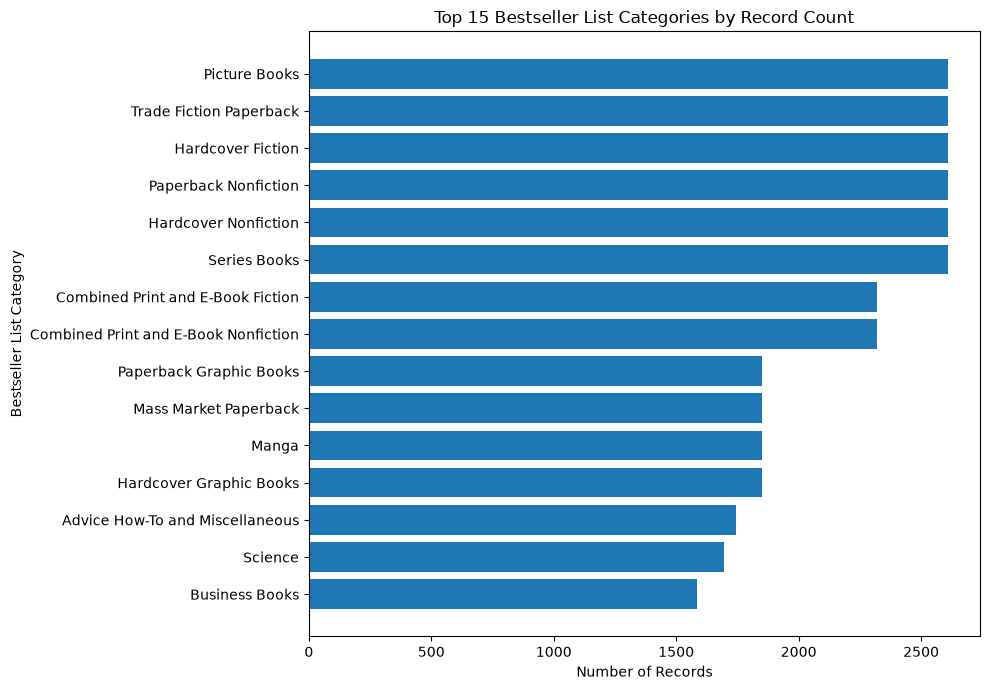


Rank summary:
+-----------+------------+------------+---------+-----------+
|Valid_Ranks|Minimum_Rank|Maximum_Rank|Mean_Rank|Median_Rank|
+-----------+------------+------------+---------+-----------+
|61430      |1           |5           |3.0      |3          |
+-----------+------------+------------+---------+-----------+


Weeks on list summary:
+------------+-------------+-------------+-----------------+------------+
|Valid_Values|Minimum_Weeks|Maximum_Weeks|Mean_Weeks       |Median_Weeks|
+------------+-------------+-------------+-----------------+------------+
|61430       |0            |607          |24.70626729610939|2           |
+------------+-------------+-------------+-----------------+------------+



In [11]:

# 5.2 Distribution of Bestseller List Categories and Ranks

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

# Normalise the literal "None" marker in ISBN-10 in a working DataFrame
# The original raw CSV remains unchanged.
spark_books_eda = spark_books_multiline.withColumn(
    "isbn10",
    F.when(
        F.trim(F.col("isbn10")) == "None",
        F.lit(None).cast("string")
    ).otherwise(F.col("isbn10"))
)

print("Effective missing ISBN-10 values after normalisation:")
spark_books_eda.select(
    F.sum(
        F.when(F.col("isbn10").isNull(), 1).otherwise(0)
    ).alias("Missing_ISBN10")
).show()

# Summarise records by list category
category_summary = (
    spark_books_eda
    .groupBy("list_name")
    .agg(
        F.count("*").alias("Record_Count"),
        F.countDistinct("published_date").alias("Distinct_Dates"),
        F.countDistinct("isbn13").alias("Distinct_ISBN13")
    )
    .orderBy(F.desc("Record_Count"))
)

print("\nList category summary:")
category_summary.show(20, truncate=False)

# Convert the summary to Pandas for plotting
category_pd = category_summary.toPandas()

# Plot the 15 categories with the most records
top_categories = category_pd.head(15).sort_values("Record_Count")

plt.figure(figsize=(10, 7))
plt.barh(
    top_categories["list_name"],
    top_categories["Record_Count"]
)
plt.title("Top 15 Bestseller List Categories by Record Count")
plt.xlabel("Number of Records")
plt.ylabel("Bestseller List Category")
plt.tight_layout()
plt.show()

# Convert rank and weeks_on_list to numeric values for analysis
spark_books_eda = (
    spark_books_eda
    .withColumn("rank_numeric", F.col("rank").cast("integer"))
    .withColumn("weeks_on_list_numeric", F.col("weeks_on_list").cast("integer"))
)

print("\nRank summary:")
spark_books_eda.select(
    F.count("rank_numeric").alias("Valid_Ranks"),
    F.min("rank_numeric").alias("Minimum_Rank"),
    F.max("rank_numeric").alias("Maximum_Rank"),
    F.avg("rank_numeric").alias("Mean_Rank"),
    F.expr("percentile_approx(rank_numeric, 0.5)").alias("Median_Rank")
).show(truncate=False)

print("\nWeeks on list summary:")
spark_books_eda.select(
    F.count("weeks_on_list_numeric").alias("Valid_Values"),
    F.min("weeks_on_list_numeric").alias("Minimum_Weeks"),
    F.max("weeks_on_list_numeric").alias("Maximum_Weeks"),
    F.avg("weeks_on_list_numeric").alias("Mean_Weeks"),
    F.expr("percentile_approx(weeks_on_list_numeric, 0.5)").alias("Median_Weeks")
).show(truncate=False)


### 5.3 Bestseller List Categories, Rankings and Weeks on the List

The category analysis shows that record counts vary across bestseller list categories. Six categories each contain 2,610 records, while other categories contain fewer records. These differences may reflect the frequency and historical coverage of the respective lists. However, category record counts should not be interpreted as counts of unique books because the same book may appear on multiple dates or lists.

The rank variable ranges from 1 to 5, with a mean and median of 3. This is consistent with the dataset recording the top five entries for each list publication date. Rank describes the relative position of a book after it has appeared on a list, but it would introduce target leakage if used to predict bestseller list membership before that event occurs.

The weeks-on-list variable ranges from 0 to 607 weeks. Its mean is approximately 24.71 weeks, compared with a median of 2 weeks. This difference indicates a strongly right-skewed distribution in which a relatively small number of large values influence the mean. The following analyses investigate this pattern and examine the unusually frequent zero values.

Overall, the NYT dataset provides useful historical information about list membership and subsequent list performance. However, these variables do not all represent suitable predictors for a pre-listing classification task. The final feature set must be based on information that would be available at the intended prediction point, and the dataset must be combined with an appropriate comparison population to support binary classification.


Weeks-on-list distribution summary:
+-------------+----------+--------------+--------------+---------------+---------------+---------------+
|Total_Records|Zero_Weeks|Negative_Weeks|Above_52_Weeks|90th_Percentile|95th_Percentile|99th_Percentile|
+-------------+----------+--------------+--------------+---------------+---------------+---------------+
|61430        |20415     |0             |7768          |69             |133            |363            |
+-------------+----------+--------------+--------------+---------------+---------------+---------------+


Records with the highest weeks-on-list values:
+--------------+----------------+------------+------------------------------------+------------------------------+-------------+---------------------+
|published_date|list_name       |rank_numeric|title                               |author                        |isbn13       |weeks_on_list_numeric|
+--------------+----------------+------------+------------------------------------+-----

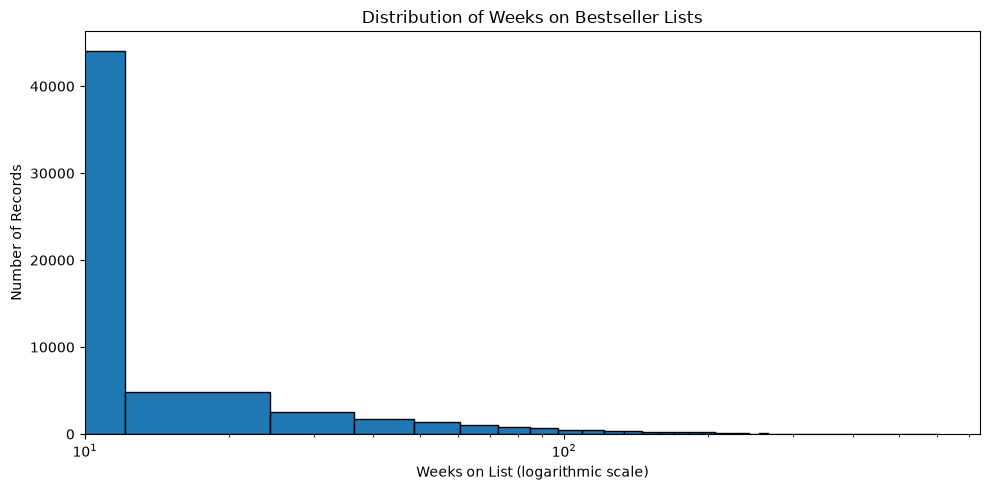

In [12]:

# 5.4 Investigating the Weeks-on-List Distribution

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Summarise weeks on the list
print("Weeks-on-list distribution summary:")

spark_books_eda.select(
    F.count("*").alias("Total_Records"),
    F.sum(
        F.when(F.col("weeks_on_list_numeric") == 0, 1).otherwise(0)
    ).alias("Zero_Weeks"),
    F.sum(
        F.when(F.col("weeks_on_list_numeric") < 0, 1).otherwise(0)
    ).alias("Negative_Weeks"),
    F.sum(
        F.when(F.col("weeks_on_list_numeric") > 52, 1).otherwise(0)
    ).alias("Above_52_Weeks"),
    F.expr(
        "percentile_approx(weeks_on_list_numeric, 0.90)"
    ).alias("90th_Percentile"),
    F.expr(
        "percentile_approx(weeks_on_list_numeric, 0.95)"
    ).alias("95th_Percentile"),
    F.expr(
        "percentile_approx(weeks_on_list_numeric, 0.99)"
    ).alias("99th_Percentile")
).show(truncate=False)

# Inspect the highest observed values
print("\nRecords with the highest weeks-on-list values:")

(
    spark_books_eda
    .select(
        "published_date",
        "list_name",
        "rank_numeric",
        "title",
        "author",
        "isbn13",
        "weeks_on_list_numeric"
    )
    .orderBy(F.desc("weeks_on_list_numeric"))
    .show(15, truncate=False)
)

# Prepare a distribution sample for visualisation
weeks_pd = (
    spark_books_eda
    .select("weeks_on_list_numeric")
    .dropna()
    .toPandas()["weeks_on_list_numeric"]
)

# Plot the distribution using a logarithmic horizontal axis
plt.figure(figsize=(10, 5))
plt.hist(weeks_pd, bins=50, edgecolor="black")
plt.xscale("log")
plt.title("Distribution of Weeks on Bestseller Lists")
plt.xlabel("Weeks on List (logarithmic scale)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()



### 5.5 Distribution and Interpretation of Weeks on the Bestseller List

The weeks-on-list analysis identified a highly right-skewed distribution. Of the 61,430 records, 20,415 (approximately 33.24%) have a recorded value of zero, while 7,768 (approximately 12.65%) have values exceeding 52 weeks. The 90th, 95th and 99th percentiles are 69, 133 and 363 weeks respectively, and the maximum observed value is 607 weeks.

The histogram confirms that observations are concentrated at the lower end of the distribution, with a long upper tail. The mean of approximately 24.71 weeks is substantially greater than the median of 2 weeks, indicating that a relatively small number of large values influence the mean.

The highest observed records include repeated weekly entries for the same ISBN and title, with the recorded weeks-on-list value increasing across dates. This suggests that the variable reflects cumulative list duration for a book rather than an independent measurement for each record.

The large number of zero values requires further investigation to determine whether zero is a valid recorded value or represents a special data convention. Repeated weekly observations must also be considered when defining the modelling unit and separating training and test data.

Because weeks on the list describes observed bestseller performance, it will not be used as a predictor for a model intended to estimate bestseller status before list entry.


Most frequent weeks-on-list values:
+---------------------+------------+
|weeks_on_list_numeric|Record_Count|
+---------------------+------------+
|0                    |20415       |
|1                    |7476        |
|2                    |3889        |
|3                    |2733        |
|4                    |2062        |
|5                    |1536        |
|6                    |1226        |
|7                    |1040        |
|8                    |914         |
|9                    |819         |
|10                   |719         |
|11                   |671         |
|12                   |606         |
|13                   |564         |
|14                   |521         |
+---------------------+------------+
only showing top 15 rows

Number of records with zero weeks on the list: 20415

Examples of zero-week records:
+--------------+-------------------------+------------+-------------------------------------+------------------------------------+-------------+------

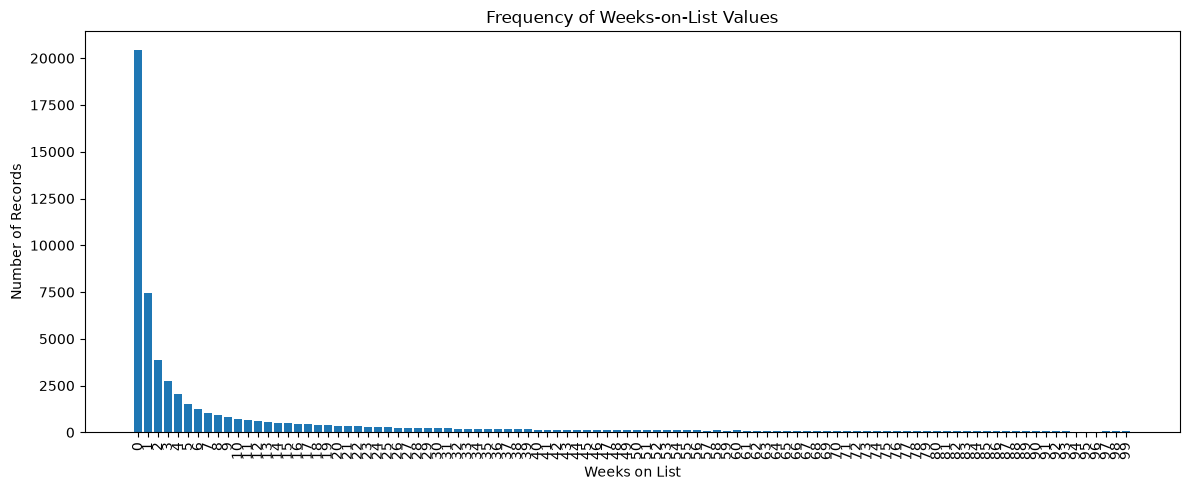

In [13]:

# 5.6 Investigating Zero Values in Weeks on the List

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Count the most frequent weeks-on-list values
print("Most frequent weeks-on-list values:")

(
    spark_books_eda
    .groupBy("weeks_on_list_numeric")
    .agg(F.count("*").alias("Record_Count"))
    .orderBy(F.desc("Record_Count"))
    .show(15, truncate=False)
)

# Filter records where weeks on the list equals zero
zero_weeks = spark_books_eda.filter(
    F.col("weeks_on_list_numeric") == 0
)

print(
    "\nNumber of records with zero weeks on the list:",
    zero_weeks.count()
)

# Display examples of zero-week records
print("\nExamples of zero-week records:")

zero_weeks.select(
    "published_date",
    "list_name",
    "rank_numeric",
    "title",
    "author",
    "isbn13",
    "weeks_on_list_numeric"
).show(20, truncate=False)

# Compare zero and non-zero values across list ranks
print("\nWeeks-on-list values by rank:")

(
    spark_books_eda
    .groupBy("rank_numeric")
    .agg(
        F.count("*").alias("Total_Records"),
        F.sum(
            F.when(
                F.col("weeks_on_list_numeric") == 0, 1
            ).otherwise(0)
        ).alias("Zero_Weeks_Records"),
        F.avg("weeks_on_list_numeric").alias("Mean_Weeks")
    )
    .orderBy("rank_numeric")
    .show(truncate=False)
)

# Visualise the frequency of the 100 lowest distinct values
weeks_frequency = (
    spark_books_eda
    .groupBy("weeks_on_list_numeric")
    .agg(F.count("*").alias("Record_Count"))
    .orderBy("weeks_on_list_numeric")
    .limit(100)
    .toPandas()
)

plt.figure(figsize=(12, 5))
plt.bar(
    weeks_frequency["weeks_on_list_numeric"].astype(str),
    weeks_frequency["Record_Count"]
)
plt.title("Frequency of Weeks-on-List Values")
plt.xlabel("Weeks on List")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



### 5.7 Investigation of Zero Weeks-on-List Values

The analysis identified 20,415 records with zero weeks on the list. Zero was the most frequent value, followed by one week with 7,476 records and two weeks with 3,889 records. No negative values were identified.

The zero values were distributed equally across all five ranks, with 4,083 zero-week records at each rank. Examples include books appearing at ranks one to five on the same publication date with zero weeks recorded.

This pattern indicates that zero is systematically represented in the dataset rather than being restricted to a small number of isolated records. However, the precise meaning of zero cannot be confirmed from the available columns alone. It may represent a source-specific recording convention, and further source documentation would be needed to establish its meaning.

The zero values will therefore be retained during the initial analysis rather than automatically treated as errors or missing values. The variable will remain descriptive and will not be used as a predictor in a model intended to predict bestseller status before list entry.


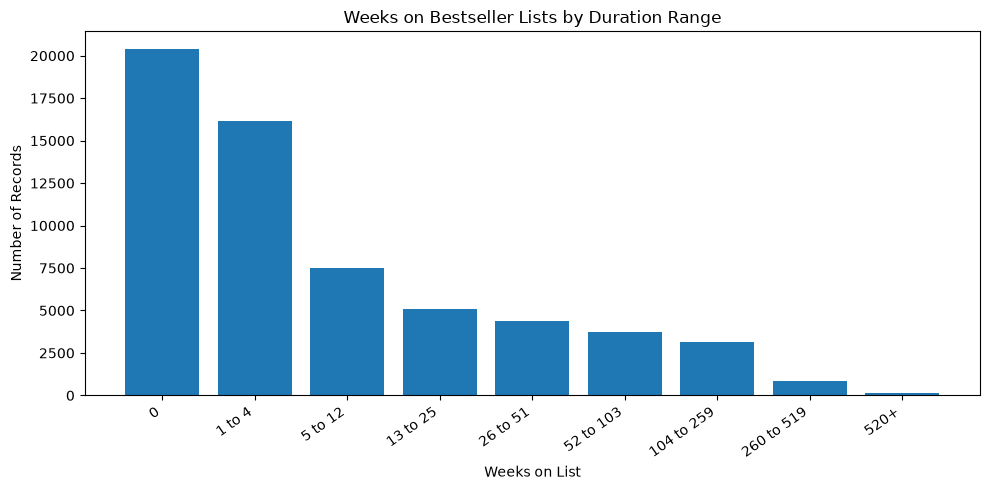

In [14]:

# Group weeks-on-list values into readable intervals

weeks_pd = (
    spark_books_eda
    .select("weeks_on_list_numeric")
    .dropna()
    .toPandas()["weeks_on_list_numeric"]
)

week_bins = [0, 1, 5, 13, 26, 52, 104, 260, 520, float("inf")]
week_labels = [
    "0",
    "1 to 4",
    "5 to 12",
    "13 to 25",
    "26 to 51",
    "52 to 103",
    "104 to 259",
    "260 to 519",
    "520+"
]

weeks_grouped = pd.cut(
    weeks_pd,
    bins=week_bins,
    labels=week_labels,
    right=False,
    include_lowest=True
)

weeks_group_counts = (
    weeks_grouped
    .value_counts(sort=False)
)

plt.figure(figsize=(10, 5))
plt.bar(
    weeks_group_counts.index.astype(str),
    weeks_group_counts.values
)
plt.title("Weeks on Bestseller Lists by Duration Range")
plt.xlabel("Weeks on List")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



### 5.8 Weeks-on-List Distribution by Duration Range

The grouped histogram provides a clearer view of the distribution of weeks on bestseller lists. The largest group contains records with zero weeks, followed by records with one to four weeks. Record counts generally decrease as the duration range increases, although a substantial number of observations extend beyond one year.

This pattern confirms that the weeks-on-list variable is strongly concentrated at shorter durations, with a smaller number of observations at much longer durations. Grouping the values makes this pattern easier to interpret than plotting every individual value.

The variable provides useful descriptive information about historical list performance. However, it will not be used as a predictor for the intended pre-listing classification task because it reflects observed performance rather than information available before list entry.


### 5.9 Summary of EDA Findings and Modelling Implications

The exploratory analysis identified several characteristics that influence the subsequent modelling process.

| EDA finding | Interpretation | Modelling implication |
|---|---|---|
| Bestseller list categories contain different record counts. | List coverage and record frequency vary across categories. | Interpret category counts as list entries, not unique books. |
| Rank ranges from 1 to 5. | The variable describes a book's position on an observed bestseller list. | Exclude rank from predictors for pre-listing classification to avoid target leakage. |
| Weeks on the list ranges from 0 to 607, with a mean substantially above its median. | The distribution is strongly right-skewed, with a long upper tail. | Investigate unusual values and avoid assuming that extreme values are errors without supporting evidence. |
| Zero weeks is common and occurs across all five ranks. | Zero is a systematic recorded value, but its exact meaning cannot be confirmed from the available fields alone. | Retain it during the initial investigation and avoid unsupported recoding. |
| The same book may occur in multiple weekly records or categories. | The record count does not equal the number of distinct books. | Use book identifiers to construct the modelling population and consider duplicate or related records when splitting the data. |
| The NYT source primarily contains observed bestseller list entries. | It does not independently provide a verified negative class. | Investigate a second metadata source and define the target in terms of observed NYT list membership. |

These findings inform the next stage of the project, which investigates the feasibility of constructing a binary target variable. The analysis distinguishes observed NYT list membership from the absence of a match, since an unmatched record cannot automatically be assumed to be a verified non-bestseller.


# 6. Target Variable Feasibility and Dataset Expansion

### 6.1 Defining the Classification Target

The classification task is to predict whether a book's ISBN-13 identifier is observed in the selected New York Times (NYT) bestseller records. The target variable is binary, with 1 representing an observed match and 0 representing no observed match.

The NYT dataset supplies evidence for the positive class, while the Goodreads Book Graph provides a broader collection of book metadata from which a comparison class can be constructed. ISBN-13 is used as the primary matching identifier because it provides a standardised identifier for a particular book edition.

A match establishes that the identifier appears in both sources. However, a non-match does not prove that a book has never been a bestseller. Books may be absent because of differences in source coverage, publication periods, edition identifiers or missing and invalid ISBN values.

Consequently, the target is interpreted as **observed NYT bestseller-list membership within the selected records**, rather than definitive commercial bestseller status. This distinction is important when assessing dataset suitability, interpreting model performance and describing the conclusions of the study.

## 6.2 Establishing the Number of Identifiable Bestseller Books

Before merging datasets, the number of distinct ISBN-13 identifiers and the number of records without ISBN-13 identifiers will be examined. ISBN-13 will be the preferred matching key because it can help identify the same book edition across data sources.

Repeated weekly entries will be retained in the historical data but must be consolidated appropriately when constructing a book-level classification dataset.

For this analysis, an ISBN 13 identifier is initially treated as valid when it contains exactly 13 numeric digits. This format check supports consistent matching between datasets, but it does not independently confirm the ISBN check digit or establish that the identifier represents a distinct book title. Duplicate identifiers are therefore removed before cross dataset matching.


In [15]:

# 6.3 Quantifying Identifiable Bestseller Books

from pyspark.sql import functions as F

# Count list entries and ISBN-13 availability
print("Bestseller dataset identifier summary:")

spark_books_eda.select(
    F.count("*").alias("Total_List_Entries"),
    F.sum(
        F.when(
            F.col("isbn13").isNull()
            | (F.trim(F.col("isbn13")) == ""),
            1
        ).otherwise(0)
    ).alias("Missing_ISBN13_Entries"),
    F.countDistinct("isbn13").alias("Distinct_ISBN13_Values")
).show(truncate=False)

# Create a working set with normalised ISBN-13 strings
books_with_isbn = (
    spark_books_eda
    .withColumn("isbn13_clean", F.trim(F.col("isbn13")))
    .filter(
        F.col("isbn13_clean").isNotNull()
        & (F.col("isbn13_clean") != "")
    )
)

# Count distinct ISBN-13 identifiers
distinct_isbn_count = (
    books_with_isbn
    .select("isbn13_clean")
    .distinct()
    .count()
)

print("Distinct ISBN-13 identifiers:", distinct_isbn_count)

# Examine how frequently each ISBN-13 appears
isbn_frequency = (
    books_with_isbn
    .groupBy("isbn13_clean")
    .agg(
        F.count("*").alias("List_Entry_Count"),
        F.countDistinct("title").alias("Distinct_Titles"),
        F.countDistinct("list_name").alias("Distinct_List_Categories"),
        F.min("published_date_parsed").alias("First_Observed_Date"),
        F.max("published_date_parsed").alias("Last_Observed_Date")
    )
)

print("\nFrequency of ISBN-13 identifiers:")

isbn_frequency.select(
    F.count("*").alias("Distinct_ISBN13"),
    F.sum(
        F.when(F.col("List_Entry_Count") == 1, 1).otherwise(0)
    ).alias("Appearing_Once"),
    F.sum(
        F.when(F.col("List_Entry_Count") > 1, 1).otherwise(0)
    ).alias("Appearing_More_Than_Once"),
    F.max("List_Entry_Count").alias("Maximum_Entries_For_One_ISBN")
).show(truncate=False)

print("\nExamples of ISBN-13 identifiers with the most entries:")

(
    isbn_frequency
    .orderBy(F.desc("List_Entry_Count"))
    .show(10, truncate=False)
)


Bestseller dataset identifier summary:
+------------------+----------------------+----------------------+
|Total_List_Entries|Missing_ISBN13_Entries|Distinct_ISBN13_Values|
+------------------+----------------------+----------------------+
|61430             |4                     |8928                  |
+------------------+----------------------+----------------------+

Distinct ISBN-13 identifiers: 8928

Frequency of ISBN-13 identifiers:
+---------------+--------------+------------------------+----------------------------+
|Distinct_ISBN13|Appearing_Once|Appearing_More_Than_Once|Maximum_Entries_For_One_ISBN|
+---------------+--------------+------------------------+----------------------------+
|8928           |3243          |5685                    |374                         |
+---------------+--------------+------------------------+----------------------------+


Examples of ISBN-13 identifiers with the most entries:
+-------------+----------------+---------------+---------------

### 6.4 Verification of the Goodreads Metadata File

The Goodreads Book Graph metadata file will be inspected in its compressed form before further processing. This step verifies that the file exists in the expected project directory, records its file size, and checks whether an individual JSON record can be read successfully.

The file will not be fully extracted at this stage. Inspecting a single record first allows the dataset structure and available variables to be assessed before deciding how to process the larger dataset. The original NYT bestseller dataset will remain unchanged.

### 6.5 Verification of the Goodreads File Format

The downloaded Goodreads file is present in the raw data directory, but its filename differs from the expected compressed `.json.gz` format. Before processing the dataset, the file's actual format and size will be checked to determine whether it is compressed or already extracted. The source file will remain unchanged during this verification.

The downloaded Goodreads metadata file is inspected to establish its format, structure and suitability for record level processing before the full dataset is scanned.

In [20]:
from pathlib import Path

# Locate the project root from the Notebooks folder.
project_dir = Path.cwd().parent

# Define the data directories.
raw_data_dir = project_dir / "Data" / "Raw"
processed_data_dir = project_dir / "Data" / "Processed"

# Locate and verify the Goodreads source file.
goodreads_path = raw_data_dir / "goodreads_books.json"

print("Project directory:", project_dir)
print("Raw data directory:", raw_data_dir)
print("Processed data directory:", processed_data_dir)
print("Goodreads file exists:", goodreads_path.exists())

if goodreads_path.exists():
    print(f"File size: {goodreads_path.stat().st_size / (1024**3):.2f} GB")

    with goodreads_path.open("rb") as file:
        file_signature = file.read(4)

    print("First four bytes:", file_signature)
    print("Gzip signature detected:", file_signature[:2] == b"\x1f\x8b")
else:
    print("Goodreads file not found. Check the project directory.")



Project directory: C:\Users\rohin\Part_2_Logistic_Regression
Raw data directory: C:\Users\rohin\Part_2_Logistic_Regression\Data\Raw
Processed data directory: C:\Users\rohin\Part_2_Logistic_Regression\Data\Processed
Goodreads file exists: True
File size: 3.97 GB
First four bytes: b'{"is'
Gzip signature detected: False


### 6.6 Initial Inspection of Goodreads Metadata

The file signature indicates that the Goodreads dataset is stored as JSON text rather than gzip compressed data. The next step is to inspect a single record to identify the available metadata fields and assess their potential relevance to the classification task. Only one line will be read at this stage to avoid loading the full dataset into memory.

In [21]:
import json

with goodreads_path.open("r", encoding="utf-8") as file:
    first_line = file.readline()

first_record = json.loads(first_line)

print("First record read successfully.")
print("\nAvailable fields:")
print(list(first_record.keys()))

print("\nSelected field examples:")
for field in [
    "isbn", "isbn13", "title", "authors",
    "publication_year", "publisher", "num_pages",
    "average_rating", "ratings_count"
]:
    print(f"{field}: {first_record.get(field)}")


First record read successfully.

Available fields:
['isbn', 'text_reviews_count', 'series', 'country_code', 'language_code', 'popular_shelves', 'asin', 'is_ebook', 'average_rating', 'kindle_asin', 'similar_books', 'description', 'format', 'link', 'authors', 'publisher', 'num_pages', 'publication_day', 'isbn13', 'publication_month', 'edition_information', 'publication_year', 'url', 'image_url', 'book_id', 'ratings_count', 'work_id', 'title', 'title_without_series']

Selected field examples:
isbn: 0312853122
isbn13: 9780312853129
title: W.C. Fields: A Life on Film
authors: [{'author_id': '604031', 'role': ''}]
publication_year: 1984
publisher: St. Martin's Press
num_pages: 256
average_rating: 4.00
ratings_count: 3


### 6.7 Preliminary ISBN13 Quality Assessment

ISBN13 will be used as the primary key for matching Goodreads book metadata to the NYT bestseller dataset. Before performing a full dataset comparison, a small sample of Goodreads records will be inspected to assess ISBN13 completeness and formatting. This preliminary assessment is not a substitute for full dataset validation, but it will help identify potential data quality issues before large scale processing.

In [22]:
import json
import pandas as pd

sample_records = []

with goodreads_path.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file):
        if line_number >= 1000:
            break
        if line.strip():
            sample_records.append(json.loads(line))

goodreads_sample = pd.DataFrame(sample_records)

print("Records inspected:", len(goodreads_sample))
print("Columns available:", len(goodreads_sample.columns))

# Check ISBN13 completeness and formatting
isbn13 = goodreads_sample["isbn13"].astype("string").str.strip()

missing_isbn13 = (
    isbn13.isna() | isbn13.eq("") | isbn13.eq("nan")
)

valid_isbn13 = (
    isbn13.str.fullmatch(r"\d{13}", na=False)
    & ~missing_isbn13
)

print("\nISBN13 quality in the sample")
print("Missing ISBN13:", int(missing_isbn13.sum()))
print("13-digit ISBN13:", int(valid_isbn13.sum()))
print("Other ISBN13 formats:", int((~missing_isbn13 & ~valid_isbn13).sum()))

print("\nExample ISBN13 values:")
print(goodreads_sample["isbn13"].head(10).to_list())

print("\nSample titles and ISBN13 values:")
print(
    goodreads_sample[["title", "isbn13"]]
    .head(10)
    .to_string(index=False)
)

Records inspected: 1000
Columns available: 29

ISBN13 quality in the sample
Missing ISBN13: 352
13-digit ISBN13: 646
Other ISBN13 formats: 2

Example ISBN13 values:
['9780312853129', '9780743509985', '', '9780743294294', '9780850308716', '9781599150604', '9780425040881', '9781934876565', '9781370889471', '9780922915118']

Sample titles and ISBN13 values:
                                                               title        isbn13
                                         W.C. Fields: A Life on Film 9780312853129
                                                         Good Harbor 9780743509985
                 The Unschooled Wizard (Sun Wolf and Starhawk, #1-2)              
                                                Best Friends Forever 9780743294294
Runic Astrology: Starcraft and Timekeeping in the Northern Tradition 9780850308716
                                       The Aeneid for Boys and Girls 9781599150604
                                               The Wanting of 

### 6.8 Preparation of NYT ISBN13 Identifiers

The NYT dataset contains repeated records because a book can appear on multiple weekly bestseller lists or in different list categories. For book level matching, the ISBN13 identifiers will be standardised and deduplicated. Missing identifiers will be excluded from the matching key but retained in the original source dataset. This prevents repeated weekly entries from inflating the number of distinct matched books.

In [23]:
from pyspark.sql import functions as F

# Use the existing Spark DataFrame from the NYT dataset analysis.
# spark_books_eda has already had literal "None" ISBN10 values normalised.
nyt_isbn_check = spark_books_eda.withColumn(
    "isbn13_clean",
    F.trim(F.col("isbn13"))
)

# Treat blank strings and literal missing-value markers as null
nyt_isbn_check = nyt_isbn_check.withColumn(
    "isbn13_clean",
    F.when(
        F.col("isbn13_clean").isNull()
        | (F.col("isbn13_clean") == "")
        | (F.lower(F.col("isbn13_clean")) == "none")
        | (F.lower(F.col("isbn13_clean")) == "nan"),
        F.lit(None).cast("string")
    ).otherwise(F.col("isbn13_clean"))
)

nyt_isbn_valid = nyt_isbn_check.filter(
    F.col("isbn13_clean").rlike(r"^[0-9]{13}$")
)

nyt_unique_isbns = (
    nyt_isbn_valid
    .select(F.col("isbn13_clean").alias("isbn13"))
    .distinct()
)

print("NYT dataset ISBN13 validation")
print("Total NYT records:", spark_books_eda.count())
print("Missing or blank ISBN13 records:", 
      nyt_isbn_check.filter(F.col("isbn13_clean").isNull()).count())
print("Records with 13-digit ISBN13:", nyt_isbn_valid.count())
print("Unique valid ISBN13 identifiers:", nyt_unique_isbns.count())

print("\nSample of unique NYT ISBN13 identifiers:")
nyt_unique_isbns.show(10, truncate=False)


NYT dataset ISBN13 validation
Total NYT records: 61430
Missing or blank ISBN13 records: 4
Records with 13-digit ISBN13: 61242
Unique valid ISBN13 identifiers: 8862

Sample of unique NYT ISBN13 identifiers:
+-------------+
|isbn13       |
+-------------+
|9780399156243|
|9780316073394|
|9780385343169|
|9780425236758|
|9781401231507|
|9780230110267|
|9780446583145|
|9780446585026|
|9780312594428|
|9781455515530|
+-------------+
only showing top 10 rows


### 6.9 Goodreads and NYT ISBN13 Matching

The Goodreads metadata file will be processed one record at a time to manage memory usage. Each Goodreads ISBN13 value will be normalised and compared with the validated set of unique NYT ISBN13 identifiers. The analysis will quantify the number of Goodreads records with valid identifiers, the number of matching records, and the number of unique matching ISBN13 values.

This is a preliminary identifier matching exercise. A match indicates that an ISBN13 appears in the selected NYT bestseller dataset, while a non-match indicates only that the identifier was not found in that dataset.

In [24]:
import json

with goodreads_path.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        if not line.strip():
            continue

        try:
            json.loads(line)
        except json.JSONDecodeError as error:
            print("First invalid JSON record found")
            print("Line number:", line_number)
            print("Error:", error.msg)
            print("Column:", error.colno)
            print("Character position:", error.pos)
            print("Line length:", len(line))

            start = max(0, error.pos - 150)
            end = min(len(line), error.pos + 150)

            print("\nExcerpt around the error:")
            print(repr(line[start:end]))
            break
    else:
        print("No invalid JSON lines found.")


First invalid JSON record found
Line number: 1092948
Error: Unterminated string starting at
Column: 599
Character position: 598
Line length: 599

Excerpt around the error:
'ok"}, {"count": "3", "name": "kindle-freebie"}, {"count": "2", "name": "kindle-books"}, {"count": "2", "name": "kindle-free"}, {"count": "2", "name": "'


### 6.10 Investigation of Malformed Goodreads Records

During the preliminary matching process, a JSON decoding error was identified at line 1,092,948. The error occurs within a `popular_shelves` entry and indicates that the record cannot be parsed as a complete JSON object. The surrounding records will be inspected to determine whether the issue is isolated or indicative of a broader file integrity problem. The original dataset will remain unchanged.

In [25]:
from itertools import islice
import json

start_line = 1_092_945
end_line = 1_092_951

with goodreads_path.open("r", encoding="utf-8") as file:
    nearby_lines = islice(file, start_line - 1, end_line)

    for line_number, line in enumerate(nearby_lines, start=start_line):
        try:
            record = json.loads(line)
            print(
                f"Line {line_number}: VALID JSON | "
                f"Title: {record.get('title', 'Unavailable')}"
            )
        except json.JSONDecodeError as error:
            print(
                f"Line {line_number}: INVALID JSON | "
                f"Length: {len(line)} | Error: {error.msg}"
            )
            print("Ending excerpt:", repr(line[-120:]))


Line 1092945: VALID JSON | Title: مكونات التيار الإسلامي في سوريا: المصلحون السياسيون، العلماء والديمقراطية
Line 1092946: VALID JSON | Title: Regras da comida
Line 1092947: VALID JSON | Title: Deadly Trail
Line 1092948: INVALID JSON | Length: 599 | Error: Unterminated string starting at
Ending excerpt: 'indle-freebie"}, {"count": "2", "name": "kindle-books"}, {"count": "2", "name": "kindle-free"}, {"count": "2", "name": "'


These results are based on a preliminary sample of 1,000 records and are used to identify potential data quality issues before full dataset processing. They should not be interpreted as the definitive missingness or validity rates for the complete Goodreads dataset.

In [26]:
import json
import re

# Use the validated, unique NYT ISBN13 identifiers.
nyt_isbn_set = {
    row["isbn13"]
    for row in nyt_unique_isbns.toLocalIterator()
}

total_lines = 0
valid_json_records = 0
malformed_records = 0
missing_or_invalid_isbn13 = 0
valid_goodreads_isbn13 = 0
matching_records = 0

unique_goodreads_isbns = set()
unique_matching_isbns = set()

with goodreads_path.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        total_lines += 1

        if not line.strip():
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            malformed_records += 1
            continue

        valid_json_records += 1

        raw_isbn13 = record.get("isbn13")
        isbn13 = (
            str(raw_isbn13).strip()
            if raw_isbn13 is not None
            else ""
        )

        if not re.fullmatch(r"\d{13}", isbn13):
            missing_or_invalid_isbn13 += 1
            continue

        valid_goodreads_isbn13 += 1
        unique_goodreads_isbns.add(isbn13)

        if isbn13 in nyt_isbn_set:
            matching_records += 1
            unique_matching_isbns.add(isbn13)

print("GOODREADS AND NYT ISBN13 MATCHING RESULTS")
print("-" * 45)
print("Total lines read:", total_lines)
print("Valid JSON records:", valid_json_records)
print("Malformed JSON records skipped:", malformed_records)
print("Records with missing or invalid ISBN13:",
      missing_or_invalid_isbn13)
print("Records with valid 13-digit ISBN13:",
      valid_goodreads_isbn13)
print("Unique valid Goodreads ISBN13:", len(unique_goodreads_isbns))
print("Matching Goodreads records:", matching_records)
print("Unique matching ISBN13:", len(unique_matching_isbns))

if valid_goodreads_isbn13:
    print(
        "Record-level match rate:",
        f"{matching_records / valid_goodreads_isbn13:.2%}"
    )

if unique_goodreads_isbns:
    print(
        "Unique ISBN13 match rate:",
        f"{len(unique_matching_isbns) / len(unique_goodreads_isbns):.2%}"
    )

GOODREADS AND NYT ISBN13 MATCHING RESULTS
---------------------------------------------
Total lines read: 1092948
Valid JSON records: 1092947
Malformed JSON records skipped: 1
Records with missing or invalid ISBN13: 364467
Records with valid 13-digit ISBN13: 728480
Unique valid Goodreads ISBN13: 728480
Matching Goodreads records: 3207
Unique matching ISBN13: 3207
Record-level match rate: 0.44%
Unique ISBN13 match rate: 0.44%


### 6.11 Validation of Goodreads File Completeness

The initial Goodreads scan ended at the same line as the first malformed JSON record. This raises the possibility that the downloaded file is incomplete or truncated. The file ending and record count will be checked before the matching results are accepted. This validation is necessary to ensure that the combined dataset is based on a sufficiently complete source.

In [27]:
# Inspect the end of the downloaded file without loading it all into memory
with goodreads_path.open("rb") as file:
    file.seek(0, 2)
    file_size = file.tell()

    print(f"File size: {file_size / (1024**3):.2f} GB")

    file.seek(max(0, file_size - 500))
    ending = file.read()

print("\nLast 500 bytes of the file:")
print(repr(ending))

print("\nDoes the file end with a closing brace? ",
      ending.rstrip().endswith(b"}"))

File size: 3.97 GB

Last 500 bytes of the file:
b'opular_shelves": [{"count": "204", "name": "to-read"}, {"count": "11", "name": "romantic-suspense"}, {"count": "6", "name": "romance"}, {"count": "6", "name": "kindle"}, {"count": "6", "name": "freebie"}, {"count": "5", "name": "currently-reading"}, {"count": "4", "name": "freebies"}, {"count": "4", "name": "suspense"}, {"count": "3", "name": "ebook"}, {"count": "3", "name": "kindle-freebie"}, {"count": "2", "name": "kindle-books"}, {"count": "2", "name": "kindle-free"}, {"count": "2", "name": "'

Does the file end with a closing brace?  False


In [28]:
from pathlib import Path
import json

downloads_path = Path(
    r"C:\Users\rohin\Downloads\goodreads_books.json\goodreads_books"
)

print("File exists:", downloads_path.is_file())

if downloads_path.is_file():
    print(f"File size: {downloads_path.stat().st_size / (1024**3):.2f} GB")

    # Check the beginning of the file
    with downloads_path.open("rb") as file:
        first_line = file.readline()

    try:
        first_record = json.loads(first_line)
        print("First record: valid JSON")
        print("First record title:", first_record.get("title"))
    except json.JSONDecodeError as error:
        print("First record could not be parsed:", error)

    # Check the final record
    with downloads_path.open("rb") as file:
        file.seek(0, 2)
        file_size = file.tell()
        file.seek(max(0, file_size - 100_000))
        ending = file.read().decode("utf-8", errors="replace")

    last_nonempty_line = next(
        (line for line in reversed(ending.splitlines()) if line.strip()),
        ""
    )

    print("\nFile ends with a closing brace:", ending.rstrip().endswith("}"))

    try:
        last_record = json.loads(last_nonempty_line)
        print("Final record: valid JSON")
        print("Final record title:", last_record.get("title"))
    except json.JSONDecodeError as error:
        print("Final record could not be parsed:", error)

File exists: False


In [29]:
from pathlib import Path

downloads_dir = Path.home() / "Downloads"

print("Downloads folder:", downloads_dir)
print("\nMatching files and folders:")

for item in downloads_dir.glob("goodreads_books.json*"):
    print(
        "Name:", item.name,
        "| Is file:", item.is_file(),
        "| Is folder:", item.is_dir()
    )

    if item.is_dir():
        for child in item.iterdir():
            print(
                "   Inside:", child.name,
                "| Is file:", child.is_file(),
                "| Size (GB):",
                f"{child.stat().st_size / (1024**3):.2f}"
                if child.is_file() else "N/A"
            )

Downloads folder: C:\Users\rohin\Downloads

Matching files and folders:
Name: goodreads_books.json | Is file: False | Is folder: True
   Inside: goodreads_books.json | Is file: True | Size (GB): 8.57
Name: goodreads_books.json.gz | Is file: True | Is folder: False


In [30]:
from pathlib import Path
import gzip
import json

downloads_dir = Path.home() / "Downloads"

extracted_path = (
    downloads_dir / "goodreads_books.json" / "goodreads_books.json"
)
compressed_path = downloads_dir / "goodreads_books.json.gz"

# Check the extracted file
print("EXTRACTED FILE")
print("Exists:", extracted_path.is_file())

if extracted_path.is_file():
    print(f"Size: {extracted_path.stat().st_size / (1024**3):.2f} GB")

    with extracted_path.open("rb") as file:
        first_line = file.readline()

    try:
        first_record = json.loads(first_line)
        print("First record valid:", True)
        print("First title:", first_record.get("title"))
    except (json.JSONDecodeError, UnicodeDecodeError) as error:
        print("First record valid:", False, "|", error)

    with extracted_path.open("rb") as file:
        file.seek(0, 2)
        file_size = file.tell()
        file.seek(max(0, file_size - 100_000))
        ending = file.read().decode("utf-8", errors="replace")

    last_line = next(
        (line for line in reversed(ending.splitlines()) if line.strip()),
        ""
    )

    try:
        last_record = json.loads(last_line)
        print("Last record valid:", True)
        print("Last title:", last_record.get("title"))
    except (json.JSONDecodeError, UnicodeDecodeError) as error:
        print("Last record valid:", False, "|", error)

# Test the compressed file by reading it to the end
print("\nCOMPRESSED FILE")
print("Exists:", compressed_path.is_file())

if compressed_path.is_file():
    print(f"Size: {compressed_path.stat().st_size / (1024**3):.2f} GB")

    try:
        decompressed_bytes = 0

        with gzip.open(compressed_path, "rb") as file:
            while True:
                chunk = file.read(8 * 1024 * 1024)
                if not chunk:
                    break
                decompressed_bytes += len(chunk)

        print("Gzip stream completed successfully.")
        print(f"Uncompressed bytes read: {decompressed_bytes:,}")

    except (OSError, EOFError) as error:
        print("Gzip verification failed:", repr(error))

EXTRACTED FILE
Exists: True
Size: 8.57 GB
First record valid: True
First title: W.C. Fields: A Life on Film
Last record valid: True
Last title: The Spanish Duke's Virgin Bride (Innocent Mistress, Virgin Bride, #1) (Harlequin Presents, #2679)

COMPRESSED FILE
Exists: True
Size: 1.94 GB
Gzip stream completed successfully.
Uncompressed bytes read: 9,202,235,168


The initial scan did not process the complete source file because it stopped at the malformed JSON record. Its record count is therefore treated as a diagnostic result rather than the definitive dataset total. The subsequent full scan is used to establish the accepted record counts and matching results.

### 6.12 Full ISBN13 Matching Using the Verified Goodreads File

The original Goodreads compressed archive was read to completion without a gzip integrity error, and its uncompressed byte count matched the size reported for the larger extracted JSON file. The extracted file will therefore be used for a full record level validation and ISBN13 matching scan.

Each nonempty line will be parsed as an individual JSON record. Malformed records will be counted explicitly, and valid ISBN13 identifiers will be compared against the deduplicated NYT identifier set. The results will be used to assess the overlap between the datasets before the classification target is constructed.

In [31]:
import json
import re
from pathlib import Path

# Use the larger extracted file verified in Downloads.
extracted_path = (
    Path.home() / "Downloads" /
    "goodreads_books.json" / "goodreads_books.json"
)

assert extracted_path.is_file(), (
    f"Goodreads file not found: {extracted_path}"
)

# Use the previously validated set of unique NYT ISBN13 identifiers.
nyt_isbn_set = {
    row["isbn13"]
    for row in nyt_unique_isbns.toLocalIterator()
}

total_lines = 0
blank_lines = 0
valid_json_records = 0
malformed_records = 0
missing_or_invalid_isbn13 = 0
valid_goodreads_isbn13 = 0
matching_records = 0

unique_goodreads_isbns = set()
unique_matching_isbns = set()

with extracted_path.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file, start=1):
        total_lines += 1

        if not line.strip():
            blank_lines += 1
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            malformed_records += 1
            continue

        valid_json_records += 1

        raw_isbn13 = record.get("isbn13")
        isbn13 = (
            str(raw_isbn13).strip()
            if raw_isbn13 is not None
            else ""
        )

        if not re.fullmatch(r"\d{13}", isbn13):
            missing_or_invalid_isbn13 += 1
            continue

        valid_goodreads_isbn13 += 1
        unique_goodreads_isbns.add(isbn13)

        if isbn13 in nyt_isbn_set:
            matching_records += 1
            unique_matching_isbns.add(isbn13)

print("FULL GOODREADS AND NYT MATCHING RESULTS")
print("=" * 48)
print("Total lines read:", total_lines)
print("Blank lines:", blank_lines)
print("Valid JSON records:", valid_json_records)
print("Malformed JSON records:", malformed_records)
print("Records with missing or invalid ISBN13:",
      missing_or_invalid_isbn13)
print("Records with valid 13-digit ISBN13:",
      valid_goodreads_isbn13)
print("Unique valid Goodreads ISBN13:", len(unique_goodreads_isbns))
print("Matching Goodreads records:", matching_records)
print("Unique matching ISBN13:", len(unique_matching_isbns))

if valid_goodreads_isbn13:
    print(
        "Record-level match rate:",
        f"{matching_records / valid_goodreads_isbn13:.2%}"
    )

if unique_goodreads_isbns:
    print(
        "Unique ISBN13 match rate:",
        f"{len(unique_matching_isbns) / len(unique_goodreads_isbns):.2%}"
    )

FULL GOODREADS AND NYT MATCHING RESULTS
Total lines read: 2360655
Blank lines: 0
Valid JSON records: 2360655
Malformed JSON records: 0
Records with missing or invalid ISBN13: 787226
Records with valid 13-digit ISBN13: 1573429
Unique valid Goodreads ISBN13: 1573429
Matching Goodreads records: 6933
Unique matching ISBN13: 6933
Record-level match rate: 0.44%
Unique ISBN13 match rate: 0.44%


### 6.13 Assessment of Cross Dataset Coverage

The completed ISBN13 matching process identified 6,933 matching identifiers between Goodreads and the NYT bestseller dataset. Relative to the 8,862 unique valid NYT ISBN13 identifiers, this represents approximately 78.23% identifier coverage. The remaining identifiers may be absent from Goodreads, lack equivalent edition identifiers, or differ between sources.

Although the Goodreads dataset is substantially larger, only 0.44% of its valid ISBN13 identifiers matched the NYT dataset. This imbalance reflects the different coverage of the two sources and has implications for class construction and model evaluation. Unmatched Goodreads records will therefore be treated as books not observed in the selected NYT bestseller records, rather than as definitively verified non-bestsellers.

In [32]:
# Compare the matching identifiers against the complete NYT ISBN13 set.

total_nyt_isbns = len(nyt_isbn_set)
matched_nyt_isbns = len(unique_matching_isbns)
unmatched_nyt_isbns = total_nyt_isbns - matched_nyt_isbns

print("CROSS-DATASET COVERAGE")
print("=" * 40)
print("Unique valid NYT ISBN13:", total_nyt_isbns)
print("NYT ISBN13 matched in Goodreads:", matched_nyt_isbns)
print("NYT ISBN13 not matched in Goodreads:", unmatched_nyt_isbns)

if total_nyt_isbns:
    print(
        "NYT identifier coverage:",
        f"{matched_nyt_isbns / total_nyt_isbns:.2%}"
    )
    print(
        "NYT identifier not matched:",
        f"{unmatched_nyt_isbns / total_nyt_isbns:.2%}"
    )

CROSS-DATASET COVERAGE
Unique valid NYT ISBN13: 8862
NYT ISBN13 matched in Goodreads: 6933
NYT ISBN13 not matched in Goodreads: 1929
NYT identifier coverage: 78.23%
NYT identifier not matched: 21.77%


The matching analysis identified 6,933 unique ISBN 13 identifiers shared between the selected NYT records and the Goodreads metadata. This represents 78.23% of the 8,862 unique valid NYT identifiers, indicating that Goodreads contains matches for a substantial proportion of the selected NYT identifiers.

In the opposite direction, the matching identifiers represent approximately 0.44% of the 1,573,429 valid Goodreads ISBN 13 identifiers. These percentages use different denominators and should not be interpreted as equivalent measures of coverage.

The difference reflects the distinct scope and composition of the two datasets. An unmatched Goodreads identifier cannot be assumed to represent a book that has never appeared on a bestseller list, because the available NYT records cover only the selected lists and period, and differences in edition identifiers or source completeness may prevent a match. The matching results therefore support the construction of a proxy target for observed NYT list membership rather than a definitive label of commercial bestseller status.

### 6.14 Preliminary Target Definition and Classification Limitations

The proposed target variable represents observed membership in the selected NYT bestseller records. A value of 1 indicates that a Goodreads book's ISBN13 identifier matches a valid ISBN13 in the NYT dataset. A value of 0 indicates that the ISBN13 was not observed in the selected NYT records.

This target definition is a proxy for observed bestseller-list membership rather than proof that a book has or has not ever been a bestseller. The two datasets differ in coverage, and unmatched records may include books that appeared on other bestseller lists, books published outside the NYT observation period, or editions with identifiers that differ between sources. These limitations will be considered when assessing dataset suitability, interpreting model performance, and describing the conclusions.

In [33]:
import json
from collections import Counter

publication_year_counts = Counter()
field_missing_counts = Counter()
goodreads_record_count = 0

fields_to_check = [
    "publication_year",
    "publisher",
    "format",
    "num_pages",
    "authors",
    "average_rating",
    "ratings_count"
]

with extracted_path.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        record = json.loads(line)
        goodreads_record_count += 1

        for field in fields_to_check:
            value = record.get(field)

            if value is None or str(value).strip() in ("", "None"):
                field_missing_counts[field] += 1

        year = record.get("publication_year")

        try:
            year = int(str(year).strip())
            if 1000 <= year <= 2026:
                publication_year_counts[year] += 1
        except (ValueError, TypeError):
            pass

print("Goodreads records processed:", goodreads_record_count)

print("\nMissing values in selected fields")
for field in fields_to_check:
    missing = field_missing_counts[field]
    print(
        f"{field}: {missing:,} "
        f"({missing / goodreads_record_count:.2%})"
    )

print("\nPublication year summary")
valid_year_records = sum(publication_year_counts.values())
print("Records with plausible publication years:", valid_year_records)

if publication_year_counts:
    print("Earliest year:", min(publication_year_counts))
    print("Latest year:", max(publication_year_counts))

    print("\nMost frequent publication years:")
    for year, count in publication_year_counts.most_common(15):
        print(f"{year}: {count:,}")

Goodreads records processed: 2360655

Missing values in selected fields
publication_year: 599,625 (25.40%)
publisher: 654,376 (27.72%)
format: 646,754 (27.40%)
num_pages: 764,133 (32.37%)
authors: 0 (0.00%)
average_rating: 524 (0.02%)
ratings_count: 524 (0.02%)

Publication year summary
Records with plausible publication years: 1759790
Earliest year: 1000
Latest year: 2025

Most frequent publication years:
2013: 163,752
2014: 156,410
2012: 151,180
2015: 135,735
2016: 122,417
2011: 116,963
2010: 91,230
2009: 77,452
2017: 73,019
2008: 68,488
2007: 60,922
2006: 51,178
2005: 45,476
2004: 39,099
2003: 35,387


The binary target is defined using ISBN 13 matching between the selected NYT bestseller records and the Goodreads metadata.

* `target = 1`: the Goodreads ISBN 13 identifier matches an identifier in the selected NYT records.
* `target = 0`: the Goodreads ISBN 13 identifier does not match an identifier in the selected NYT records.

The target represents observed NYT bestseller list membership within the available source records. A nonmatch does not establish that a book has never been a bestseller, since coverage limitations, differences between editions and missing identifiers may affect matching. The classification model therefore predicts membership in the constructed target class rather than definitive bestseller status across the entire book market.

### 6.15 Investigating Publication Years and NYT Target Alignment

The Goodreads publication year distribution was examined to assess its suitability for the classification task. The dataset contains substantial missingness in publication years, and the recorded years range from 1000 to 2025. These values require careful interpretation before the modelling population is defined.

The next analysis compares Goodreads records whose valid ISBN-13 identifiers match the selected New York Times bestseller records with those that do not match. This will help assess temporal alignment between the datasets and inform the selection of an appropriate publication year range.

A nonmatching identifier will be interpreted as an absence of observed membership in the selected NYT records, not proof that the book was never a bestseller.

In [34]:
import json
from collections import Counter

# The NYT ISBN set should already have been created in the notebook.
# It contains the unique, valid 13-digit ISBN identifiers from the NYT dataset.

year_target_counts = Counter()
missing_year_target_counts = Counter()
invalid_year_target_counts = Counter()

total_records = 0
matched_records = 0

with extracted_path.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        record = json.loads(line)
        total_records += 1

        isbn13 = str(record.get("isbn13") or "").strip()
        is_match = isbn13.isdigit() and len(isbn13) == 13 and isbn13 in nyt_isbn_set

        if is_match:
            matched_records += 1

        raw_year = record.get("publication_year")

        try:
            year = int(str(raw_year).strip())

            if 1000 <= year <= 2026:
                year_target_counts[(year, int(is_match))] += 1
            else:
                invalid_year_target_counts[int(is_match)] += 1

        except (ValueError, TypeError):
            missing_year_target_counts[int(is_match)] += 1

print(f"Total Goodreads records: {total_records:,}")
print(f"Records matching NYT ISBNs: {matched_records:,}")

print("\nPublication year summary by target")
print("Year | NYT match (1) | No observed match (0)")

for year in sorted({year for year, target in year_target_counts}):
    positive = year_target_counts[(year, 1)]
    negative = year_target_counts[(year, 0)]

    if positive or negative:
        print(f"{year} | {positive:,} | {negative:,}")

print("\nRecords with missing or unparseable publication years")
print(f"NYT match: {missing_year_target_counts[1]:,}")
print(f"No observed match: {missing_year_target_counts[0]:,}")

print("\nRecords with publication years outside the plausible range")
print(f"NYT match: {invalid_year_target_counts[1]:,}")
print(f"No observed match: {invalid_year_target_counts[0]:,}")

Total Goodreads records: 2,360,655
Records matching NYT ISBNs: 6,933

Publication year summary by target
Year | NYT match (1) | No observed match (0)
1000 | 0 | 2
1005 | 0 | 1
1007 | 0 | 1
1012 | 0 | 6
1013 | 1 | 0
1014 | 0 | 3
1015 | 0 | 2
1016 | 0 | 4
1017 | 0 | 5
1025 | 0 | 2
1065 | 0 | 1
1070 | 0 | 1
1080 | 0 | 1
1084 | 0 | 1
1093 | 0 | 1
1197 | 0 | 1
1212 | 0 | 2
1213 | 0 | 4
1214 | 0 | 1
1305 | 0 | 1
1306 | 0 | 1
1321 | 0 | 2
1325 | 0 | 1
1327 | 0 | 1
1328 | 0 | 1
1330 | 0 | 1
1331 | 0 | 1
1333 | 0 | 3
1335 | 0 | 1
1337 | 0 | 1
1340 | 0 | 2
1342 | 0 | 1
1343 | 0 | 1
1344 | 0 | 3
1345 | 0 | 2
1346 | 0 | 3
1348 | 0 | 2
1349 | 0 | 4
1350 | 0 | 2
1351 | 0 | 4
1352 | 0 | 3
1353 | 0 | 3
1354 | 0 | 4
1355 | 0 | 2
1356 | 0 | 7
1357 | 0 | 3
1358 | 0 | 3
1359 | 0 | 3
1360 | 0 | 1
1361 | 0 | 2
1362 | 0 | 8
1363 | 0 | 6
1364 | 0 | 1
1365 | 0 | 16
1366 | 0 | 3
1367 | 0 | 6
1368 | 0 | 11
1369 | 0 | 18
1370 | 0 | 19
1371 | 0 | 11
1372 | 0 | 10
1373 | 0 | 17
1374 | 0 | 16
1375 | 0 | 13
1376 | 0 

In [35]:
# Summarise the proposed 2010–2018 publication-year window
start_year = 2010
end_year = 2018

positive_in_window = sum(
    count
    for (year, target), count in year_target_counts.items()
    if start_year <= year <= end_year and target == 1
)

negative_in_window = sum(
    count
    for (year, target), count in year_target_counts.items()
    if start_year <= year <= end_year and target == 0
)

total_in_window = positive_in_window + negative_in_window

print(f"Publication year window: {start_year}–{end_year}")
print(f"Observed NYT matches: {positive_in_window:,}")
print(f"No observed NYT match: {negative_in_window:,}")
print(f"Total candidate records: {total_in_window:,}")

if total_in_window:
    print(f"Observed match proportion: "
          f"{positive_in_window / total_in_window:.2%}")

Publication year window: 2010–2018
Observed NYT matches: 6,071
No observed NYT match: 1,006,458
Total candidate records: 1,012,529
Observed match proportion: 0.60%


The full dataset scan is used to establish the record counts and ISBN matching results used in the remainder of the analysis. Records that cannot be parsed as valid JSON are excluded from matching and counted separately. This makes the data processing decision explicit and prevents malformed records from being silently treated as confirmed nonmatches.

### 6.16 Class Imbalance and Sampling Strategy

The candidate dataset contains 1,012,529 Goodreads records published between 2010 and 2018, of which 6,071 have ISBN-13 identifiers observed in the selected New York Times bestseller records. The positive class therefore represents approximately 0.60% of the candidate dataset.

This imbalance makes accuracy an unsuitable standalone evaluation metric. A classifier that predicts every record as a nonmatch could achieve approximately 99.40% accuracy without identifying any observed matches.

To create a computationally manageable modelling dataset, all observed positive matches will be retained and a reproducible random sample of nonmatching records will be selected at a ratio of 10 nonmatches per positive match. The resulting dataset will contain approximately 66,781 records.

This sampling procedure changes the class prevalence. Evaluation results will therefore be interpreted in the context of the sampled dataset, and performance metrics will not be assumed to represent the original Goodreads population. The target represents observed membership in the selected NYT records rather than definitive bestseller status.

### 6.17 Construction of the Modelling Dataset

The modelling dataset will be constructed from Goodreads records with valid 13 digit ISBN identifiers and publication years between 2010 and 2018, inclusive. Restricting the dataset to valid ISBN identifiers is necessary because the target is defined through ISBN matching against the selected New York Times records.

All eligible records with an observed NYT match will be retained. A reproducible random sample of eligible records without an observed match will then be selected at a ratio of ten nonmatches for every positive match. A fixed random seed will be used to support reproducibility.

The selected metadata fields will be retained for subsequent data quality assessment and feature selection. The original source files will remain unchanged, and the sampled dataset will be stored separately in the processed data directory.

The resulting dataset will be validated for record counts, target distribution, identifier validity and missing values before any model training takes place.

In [36]:
import json
import random
from pathlib import Path
from collections import Counter

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

START_YEAR = 2010
END_YEAR = 2018
NEGATIVE_TO_POSITIVE_RATIO = 10
RANDOM_SEED = 42

rng = random.Random(RANDOM_SEED)

# Use the complete Goodreads source file validated earlier.
# Do not use the incomplete JSON file in the project Raw folder.
source_path = extracted_path

# Save the sample in the project's processed data folder.
project_path = Path.cwd().parent
processed_path = project_path / "Data" / "Processed"
processed_path.mkdir(parents=True, exist_ok=True)

output_path = processed_path / "goodreads_nyt_modelling_sample.jsonl"

# Confirm the existing NYT ISBN set is available.
assert source_path.exists(), f"Source file not found: {source_path}"
assert nyt_isbn_set, "The NYT ISBN set is empty or unavailable."

# --------------------------------------------------
# 2. Initialise counters and sample storage
# --------------------------------------------------

positive_records = []
negative_reservoir = []

eligible_positive_count = 0
eligible_negative_count = 0
excluded_invalid_isbn_count = 0
excluded_year_count = 0

target_negative_sample_size = None

# --------------------------------------------------
# 3. Read and filter Goodreads records
# --------------------------------------------------

with source_path.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        record = json.loads(line)

        # Parse publication year.
        try:
            year = int(str(record.get("publication_year")).strip())
        except (ValueError, TypeError):
            excluded_year_count += 1
            continue

        if not START_YEAR <= year <= END_YEAR:
            excluded_year_count += 1
            continue

        # A valid ISBN-13 is required to assign the target.
        isbn13 = str(record.get("isbn13") or "").strip()

        if not (isbn13.isdigit() and len(isbn13) == 13):
            excluded_invalid_isbn_count += 1
            continue

        # The label indicates observed NYT membership.
        target = int(isbn13 in nyt_isbn_set)

        # Keep a controlled set of useful metadata fields.
        authors = record.get("authors") or []
        if not isinstance(authors, list):
            authors = []

        row = {
            "isbn13": isbn13,
            "book_id": record.get("book_id"),
            "title": record.get("title"),
            "publication_year": year,
            "publisher": record.get("publisher"),
            "format": record.get("format"),
            "num_pages": record.get("num_pages"),
            "language_code": record.get("language_code"),
            "country_code": record.get("country_code"),
            "is_ebook": record.get("is_ebook"),
            "author_count": len(authors),
            "target": target
        }

        if target == 1:
            eligible_positive_count += 1
            positive_records.append(row)

        else:
            eligible_negative_count += 1

            # The desired sample size is based on the final
            # number of eligible positive records.
            # Since positives are not known until the scan ends,
            # use a temporary reservoir and trim it afterwards.
            if len(negative_reservoir) < 100_000:
                negative_reservoir.append(row)
            else:
                replacement_index = rng.randrange(eligible_negative_count)

                if replacement_index < len(negative_reservoir):
                    negative_reservoir[replacement_index] = row

# --------------------------------------------------
# 4. Finalise the negative sample
# --------------------------------------------------

target_negative_sample_size = min(
    eligible_negative_count,
    NEGATIVE_TO_POSITIVE_RATIO * eligible_positive_count
)

if len(negative_reservoir) < target_negative_sample_size:
    raise RuntimeError(
        "The reservoir is smaller than the required sample. "
        "Increase its capacity and rerun the sampling step."
    )

rng.shuffle(negative_reservoir)
negative_records = negative_reservoir[:target_negative_sample_size]

# --------------------------------------------------
# 5. Combine and shuffle records
# --------------------------------------------------

sampled_records = positive_records + negative_records
rng.shuffle(sampled_records)

# Save as JSON Lines: one JSON object per line.
with output_path.open("w", encoding="utf-8") as output_file:
    for row in sampled_records:
        output_file.write(json.dumps(row, ensure_ascii=False) + "\n")

# --------------------------------------------------
# 6. Report the actual results
# --------------------------------------------------

print("Goodreads modelling dataset construction complete")
print(f"Publication year range: {START_YEAR}–{END_YEAR}")
print(f"Eligible positive records: {eligible_positive_count:,}")
print(f"Eligible negative records in source: {eligible_negative_count:,}")
print(f"Negative records sampled: {len(negative_records):,}")
print(f"Total records saved: {len(sampled_records):,}")
print(f"Excluded for missing or invalid year: {excluded_year_count:,}")
print(f"Excluded for invalid ISBN-13: {excluded_invalid_isbn_count:,}")
print(f"Random seed: {RANDOM_SEED}")
print(f"Output file: {output_path}")

if sampled_records:
    sampled_positive_count = sum(row["target"] == 1 for row in sampled_records)
    sampled_negative_count = sum(row["target"] == 0 for row in sampled_records)

    print(f"Saved class 1: {sampled_positive_count:,}")
    print(f"Saved class 0: {sampled_negative_count:,}")
    print(f"Saved positive proportion: {sampled_positive_count / len(sampled_records):.2%}")

Goodreads modelling dataset construction complete
Publication year range: 2010–2018
Eligible positive records: 6,071
Eligible negative records in source: 749,181
Negative records sampled: 60,710
Total records saved: 66,781
Excluded for missing or invalid year: 1,348,126
Excluded for invalid ISBN-13: 257,277
Random seed: 42
Output file: C:\Users\rohin\Part_2_Logistic_Regression\Data\Processed\goodreads_nyt_modelling_sample.jsonl
Saved class 1: 6,071
Saved class 0: 60,710
Saved positive proportion: 9.09%


### 6.18 Validation of the Sampled Dataset Using PySpark

The sampled modelling dataset was saved separately from the original Goodreads source data in JSON Lines format. PySpark will be used to verify the saved record count, inspect the target class distribution, check the publication year range and quantify missing values in the selected fields.

This validation provides an independent check that the saved dataset can be loaded successfully and that its structure is suitable for subsequent preprocessing. Missing values will be assessed before deciding how to handle them in the modelling pipeline.

PySpark is used to independently inspect the saved modelling dataset and verify its record count, target distribution, publication year range and data types. This check confirms that the saved file can be loaded for subsequent analysis and that its basic structure agrees with the dataset constructed during sampling. The validation does not, by itself, establish that all individual records are free from data quality issues.

In [37]:
from pyspark.sql import functions as F

# Load the saved modelling dataset.
sample_spark = spark.read.json(str(output_path))

# 1. Record count
record_count = sample_spark.count()
print(f"Total records loaded by Spark: {record_count:,}")

# 2. Schema
print("\nDataset schema:")
sample_spark.printSchema()

# 3. Target distribution
print("\nTarget class distribution:")
(
    sample_spark
    .groupBy("target")
    .agg(F.count("*").alias("record_count"))
    .orderBy("target")
    .show()
)

# 4. Publication year range
print("\nPublication year validation:")
sample_spark.select(
    F.min("publication_year").alias("minimum_year"),
    F.max("publication_year").alias("maximum_year"),
    F.countDistinct("publication_year").alias("distinct_years")
).show()

# 5. Missing values
print("\nMissing values by field:")

missing_expressions = [
    F.sum(
        F.when(
            F.col(column).isNull()
            | (F.trim(F.col(column).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(column)
    for column in sample_spark.columns
]

sample_spark.select(missing_expressions).show(truncate=False)

# 6. ISBN-13 validity and uniqueness
print("\nIdentifier validation:")

sample_spark.select(
    F.sum(
        F.when(
            F.col("isbn13").rlike(r"^[0-9]{13}$"), 1
        ).otherwise(0)
    ).alias("valid_isbn13_records"),
    F.countDistinct("isbn13").alias("unique_isbn13_values"),
    F.countDistinct("book_id").alias("unique_book_ids")
).show()

Total records loaded by Spark: 66,781

Dataset schema:
root
 |-- author_count: long (nullable = true)
 |-- book_id: string (nullable = true)
 |-- country_code: string (nullable = true)
 |-- format: string (nullable = true)
 |-- is_ebook: string (nullable = true)
 |-- isbn13: string (nullable = true)
 |-- language_code: string (nullable = true)
 |-- num_pages: string (nullable = true)
 |-- publication_year: long (nullable = true)
 |-- publisher: string (nullable = true)
 |-- target: long (nullable = true)
 |-- title: string (nullable = true)


Target class distribution:
+------+------------+
|target|record_count|
+------+------------+
|     0|       60710|
|     1|        6071|
+------+------------+


Publication year validation:
+------------+------------+--------------+
|minimum_year|maximum_year|distinct_years|
+------------+------------+--------------+
|        2010|        2018|             9|
+------------+------------+--------------+


Missing values by field:
+------------+-----

### 6.19 Missing Values and Feature Preparation

The Spark validation confirmed that the sampled dataset contains 66,781 records, with 6,071 observed NYT matches and 60,710 records without an observed match. All records contain valid, unique ISBN-13 identifiers and unique book IDs.

Missing values were identified in the `format`, `language_code`, `num_pages` and `publisher` fields. Language code has the highest missingness at approximately 38.79%, followed by page count at 10.96%. These patterns will be considered when selecting the initial predictor set.

The `num_pages` field was inferred as a string during JSON loading and must be converted to a numeric type. Data quality checks will be performed before feature engineering. Any imputation values and transformations used for modelling must be learned from the training data and then applied to validation and test data to avoid information leakage.

In [38]:
from pyspark.sql import functions as F

# 1. Inspect page count conversion
sample_checked = sample_spark.withColumn(
    "num_pages_numeric",
    F.expr("try_cast(num_pages AS DOUBLE)")
)

print("Page count quality:")
sample_checked.select(
    F.count("*").alias("total_records"),
    F.sum(
        F.when(F.col("num_pages").isNull(), 1).otherwise(0)
    ).alias("null_page_counts"),
    F.sum(
        F.when(
            F.col("num_pages").isNotNull()
            & F.col("num_pages_numeric").isNull(),
            1
        ).otherwise(0)
    ).alias("unparseable_page_counts"),
    F.sum(
        F.when(F.col("num_pages_numeric") <= 0, 1).otherwise(0)
    ).alias("nonpositive_page_counts"),
    F.min("num_pages_numeric").alias("minimum_pages"),
    F.expr("percentile_approx(num_pages_numeric, 0.5)").alias("median_pages"),
    F.max("num_pages_numeric").alias("maximum_pages")
).show(truncate=False)

# 2. Inspect the most frequent formats
print("\nTop book formats:")
(
    sample_spark
    .groupBy("format")
    .count()
    .orderBy(F.desc("count"))
    .show(15, truncate=False)
)

# 3. Inspect the most frequent publishers
print("\nTop publishers:")
(
    sample_spark
    .groupBy("publisher")
    .count()
    .orderBy(F.desc("count"))
    .show(15, truncate=False)
)

# 4. Inspect ebook values
print("\nEbook value distribution:")
(
    sample_spark
    .groupBy("is_ebook")
    .count()
    .orderBy(F.desc("count"))
    .show(truncate=False)
)

# 5. Check class proportions by year
print("\nTarget distribution by publication year:")
(
    sample_spark
    .groupBy("publication_year", "target")
    .count()
    .orderBy("publication_year", "target")
    .show(30, truncate=False)
)

Page count quality:
+-------------+----------------+-----------------------+-----------------------+-------------+------------+-------------+
|total_records|null_page_counts|unparseable_page_counts|nonpositive_page_counts|minimum_pages|median_pages|maximum_pages|
+-------------+----------------+-----------------------+-----------------------+-------------+------------+-------------+
|66781        |0               |7321                   |166                    |0.0          |263.0       |21104.0      |
+-------------+----------------+-----------------------+-----------------------+-------------+------------+-------------+


Top book formats:
+---------------------+-----+
|format               |count|
+---------------------+-----+
|Paperback            |35271|
|Hardcover            |15458|
|ebook                |10114|
|                     |1446 |
|Audio CD             |1432 |
|Mass Market Paperback|1114 |
|Audiobook            |483  |
|Audio                |395  |
|Kindle Edition     

### 6.20 Assessment of Feature Cardinality and Numerical Data Quality

The initial feature assessment identified missing categorical metadata and page counts that cannot be converted to valid numbers. Page counts will be converted to a numeric representation, with unparseable and nonpositive values treated as missing.

The distinct value counts of publisher, format and country code will be examined to determine an appropriate categorical encoding strategy. The training dataset will be used to learn imputation values and category groupings, which will subsequently be applied unchanged to the validation and test datasets.

In [39]:
from pyspark.sql import functions as F

# Convert page counts to numeric values.
# Invalid, missing, zero and negative values become null.
sample_checked = sample_spark.withColumn(
    "num_pages_numeric",
    F.expr("try_cast(num_pages AS DOUBLE)")
).withColumn(
    "num_pages_clean",
    F.when(
        F.col("num_pages_numeric") > 0,
        F.col("num_pages_numeric")
    )
)

print("Clean page count summary:")
sample_checked.select(
    F.count("*").alias("total_records"),
    F.sum(
        F.when(F.col("num_pages_clean").isNull(), 1).otherwise(0)
    ).alias("missing_or_invalid_pages"),
    F.min("num_pages_clean").alias("minimum_valid_pages"),
    F.expr("percentile_approx(num_pages_clean, 0.5)").alias("median_valid_pages"),
    F.expr("percentile_approx(num_pages_clean, 0.95)").alias("95th_percentile_pages"),
    F.max("num_pages_clean").alias("maximum_valid_pages")
).show(truncate=False)

# Count distinct values in candidate categorical fields.
print("\nCategorical cardinality:")

for column in ["format", "publisher", "country_code"]:
    sample_checked.select(
        F.countDistinct(column).alias("distinct_non_null_values"),
        F.sum(
            F.when(F.col(column).isNull(), 1).otherwise(0)
        ).alias("null_records")
    ).show()

# Inspect common country codes.
print("\nMost frequent country codes:")
(
    sample_checked
    .groupBy("country_code")
    .count()
    .orderBy(F.desc("count"))
    .show(15, truncate=False)
)

# Check raw ebook values and their data type.
print("\nEbook values:")
sample_checked.groupBy("is_ebook").count().show(truncate=False)

Clean page count summary:
+-------------+------------------------+-------------------+------------------+---------------------+-------------------+
|total_records|missing_or_invalid_pages|minimum_valid_pages|median_valid_pages|95th_percentile_pages|maximum_valid_pages|
+-------------+------------------------+-------------------+------------------+---------------------+-------------------+
|66781        |7487                    |1.0                |264.0             |528.0                |21104.0            |
+-------------+------------------------+-------------------+------------------+---------------------+-------------------+


Categorical cardinality:
+------------------------+------------+
|distinct_non_null_values|null_records|
+------------------------+------------+
|                     136|           0|
+------------------------+------------+

+------------------------+------------+
|distinct_non_null_values|null_records|
+------------------------+------------+
|               

The feature assessment identifies substantial variation in categorical cardinality. Format contains 136 distinct values, while publisher contains 17,470 distinct values in the sampled dataset. Direct one hot encoding of every publisher would create a large and potentially sparse feature matrix, increasing memory requirements and the risk of learning patterns specific to infrequent publishers. Publisher categories are therefore grouped during preprocessing, with the grouping rules learned from the training data and applied consistently to the validation and test sets.

The country code contains only the value US in this sample and is excluded because it provides no variation with which to distinguish the target classes. Extreme page counts are investigated rather than automatically removed, since an unusual value is not necessarily an erroneous value.

### 6.21 Training, Validation and Test Data Splitting

The validated dataset will be divided into training, validation and test subsets using a 70:15:15 ratio. Stratified splitting will be used to preserve the target class distribution and, where feasible, its distribution across publication years.

The training subset will be used to estimate preprocessing parameters and model coefficients. The validation subset will support model development and hyperparameter decisions, while the test subset will be reserved for final evaluation.

Identifiers such as ISBN-13, book ID and title will be retained for traceability but excluded from the predictor matrix. The target will also be excluded from the predictors. Preprocessing steps, including numerical imputation and categorical encoding, will be fitted using the training subset only.

In [40]:
import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

# --------------------------------------------------
# 1. Prepare the validated dataset
# --------------------------------------------------

# Convert the Spark dataset to Pandas for stratified splitting.
split_columns = [
    "isbn13",
    "book_id",
    "title",
    "publication_year",
    "publisher",
    "format",
    "num_pages_clean",
    "language_code",
    "country_code",
    "is_ebook",
    "author_count",
    "target"
]

split_df = (
    sample_checked
    .select(*split_columns)
    .toPandas()
)

# Standardise data types.
split_df["publication_year"] = split_df["publication_year"].astype(int)
split_df["target"] = split_df["target"].astype(int)
split_df["author_count"] = split_df["author_count"].astype(int)

# Convert ebook strings to actual booleans.
split_df["is_ebook"] = (
    split_df["is_ebook"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

if split_df["is_ebook"].isna().any():
    raise ValueError("Unexpected missing or invalid is_ebook values.")

# Stratify on the combination of target and publication year.
split_df["stratum"] = (
    split_df["target"].astype(str)
    + "_"
    + split_df["publication_year"].astype(str)
)

stratum_counts = split_df["stratum"].value_counts()

if stratum_counts.min() < 3:
    raise ValueError(
        "At least one target-year stratum has fewer than three records. "
        "Inspect stratum_counts before splitting."
    )

# --------------------------------------------------
# 2. First split: 70% training, 30% temporary
# --------------------------------------------------

train_df, temporary_df = train_test_split(
    split_df,
    test_size=0.30,
    random_state=42,
    stratify=split_df["stratum"]
)

# --------------------------------------------------
# 3. Second split: 15% validation, 15% test
# --------------------------------------------------

temporary_df = temporary_df.copy()

temporary_stratum_counts = temporary_df["stratum"].value_counts()

if temporary_stratum_counts.min() < 2:
    raise ValueError(
        "A temporary target-year stratum has fewer than two records. "
        "Inspect temporary_stratum_counts before splitting."
    )

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=42,
    stratify=temporary_df["stratum"]
)

# Remove helper column before saving.
train_df = train_df.drop(columns=["stratum"])
validation_df = validation_df.drop(columns=["stratum"])
test_df = test_df.drop(columns=["stratum"])

# --------------------------------------------------
# 4. Save the three datasets
# --------------------------------------------------

processed_path = Path(output_path).parent

train_path = processed_path / "goodreads_nyt_train.csv"
validation_path = processed_path / "goodreads_nyt_validation.csv"
test_path = processed_path / "goodreads_nyt_test.csv"

train_df.to_csv(train_path, index=False)
validation_df.to_csv(validation_path, index=False)
test_df.to_csv(test_path, index=False)

# --------------------------------------------------
# 5. Report split sizes and target proportions
# --------------------------------------------------

for name, dataframe in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"\n{name} set")
    print(f"Records: {len(dataframe):,}")
    print("Target counts:")
    print(dataframe["target"].value_counts().sort_index().to_dict())
    print(f"Positive proportion: {dataframe['target'].mean():.2%}")
    print(
        f"Publication years: {dataframe['publication_year'].min()}–"
        f"{dataframe['publication_year'].max()}"
    )

print("\nSaved split files:")
print(train_path)
print(validation_path)
print(test_path)

print(f"\nTotal records across splits: "
      f"{len(train_df) + len(validation_df) + len(test_df):,}")


Training set
Records: 46,746
Target counts:
{0: 42497, 1: 4249}
Positive proportion: 9.09%
Publication years: 2010–2018

Validation set
Records: 10,017
Target counts:
{0: 9105, 1: 912}
Positive proportion: 9.10%
Publication years: 2010–2018

Test set
Records: 10,018
Target counts:
{0: 9108, 1: 910}
Positive proportion: 9.08%
Publication years: 2010–2018

Saved split files:
C:\Users\rohin\Part_2_Logistic_Regression\Data\Processed\goodreads_nyt_train.csv
C:\Users\rohin\Part_2_Logistic_Regression\Data\Processed\goodreads_nyt_validation.csv
C:\Users\rohin\Part_2_Logistic_Regression\Data\Processed\goodreads_nyt_test.csv

Total records across splits: 66,781


The modelling dataset is divided into training, validation and test subsets using a stratified 70:15:15 split. Stratification maintains approximately the same target class proportions across the three subsets. The training set is used to fit preprocessing and model parameters, the validation set is used to compare model configurations and select the classification threshold, and the test set is reserved for final evaluation.

The split is performed at the record level. Although ISBN matching and identifier checks reduce some duplication risks, this approach does not guarantee that different editions or closely related records representing the same underlying work cannot occur in separate subsets. This limitation is considered when interpreting the evaluation results.

### 6.22 Validation of the Training, Validation and Test Sets

The dataset was divided into training, validation and test sets using stratified sampling based on the target and publication year. The training set contains 46,746 records, the validation set contains 10,017 records, and the test set contains 10,018 records.

The positive class proportions are approximately 9.1% in all three subsets. PySpark will now be used to independently validate the saved CSV files, confirm their class distributions and check that records have not been duplicated across the splits. The test set will remain reserved for final model evaluation.

In [41]:
from pyspark.sql import functions as F

# Load each saved CSV file using Spark.
train_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(train_path))
)

validation_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(validation_path))
)

test_spark = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(test_path))
)

splits = {
    "Training": train_spark,
    "Validation": validation_spark,
    "Test": test_spark
}

# 1. Verify record counts and class distributions.
for name, df in splits.items():
    print(f"\n{name} dataset")
    print(f"Records: {df.count():,}")

    (
        df.groupBy("target")
        .count()
        .orderBy("target")
        .show()
    )

    df.select(
        F.min("publication_year").alias("minimum_year"),
        F.max("publication_year").alias("maximum_year"),
        F.countDistinct("isbn13").alias("unique_isbns"),
        F.countDistinct("book_id").alias("unique_book_ids")
    ).show()

# 2. Check for ISBN overlap between splits.
train_isbns = train_spark.select("isbn13").distinct()
validation_isbns = validation_spark.select("isbn13").distinct()
test_isbns = test_spark.select("isbn13").distinct()

train_validation_overlap = (
    train_isbns.join(validation_isbns, on="isbn13", how="inner").count()
)

train_test_overlap = (
    train_isbns.join(test_isbns, on="isbn13", how="inner").count()
)

validation_test_overlap = (
    validation_isbns.join(test_isbns, on="isbn13", how="inner").count()
)

print("\nISBN overlap checks")
print(f"Training and validation overlap: {train_validation_overlap}")
print(f"Training and test overlap: {train_test_overlap}")
print(f"Validation and test overlap: {validation_test_overlap}")

# 3. Confirm total records.
total_split_records = sum(df.count() for df in splits.values())
print(f"\nTotal records across all splits: {total_split_records:,}")


Training dataset
Records: 46,746
+------+-----+
|target|count|
+------+-----+
|     0|42488|
|     1| 4255|
|     2|    1|
| False|    1|
|    US|    1|
+------+-----+

+------------+------------+------------+---------------+
|minimum_year|maximum_year|unique_isbns|unique_book_ids|
+------------+------------+------------+---------------+
|        #1)"|        2018|       46746|          46746|
+------------+------------+------------+---------------+


Validation dataset
Records: 10,017
+------+-----+
|target|count|
+------+-----+
|     0| 9103|
|     1|  913|
| False|    1|
+------+-----+

+------------+------------+------------+---------------+
|minimum_year|maximum_year|unique_isbns|unique_book_ids|
+------------+------------+------------+---------------+
|       #12)"|        2018|       10017|          10017|
+------------+------------+------------+---------------+


Test dataset
Records: 10,018
+------+-----+
|target|count|
+------+-----+
|     0| 9107|
|     1|  910|
| False|   

In [42]:
from pyspark.sql import functions as F

def load_split_csv(path):
    return (
        spark.read
        .option("header", True)
        .option("inferSchema", False)
        .option("multiLine", True)
        .option("quote", '"')
        .option("escape", '"')
        .csv(str(path))
    )

train_spark = load_split_csv(train_path)
validation_spark = load_split_csv(validation_path)
test_spark = load_split_csv(test_path)

splits = {
    "Training": train_spark,
    "Validation": validation_spark,
    "Test": test_spark
}

for name, df in splits.items():
    print(f"\n{name} dataset")
    print(f"Records: {df.count():,}")

    print("Target values:")
    df.groupBy("target").count().orderBy("target").show()

    print("Publication year range:")
    df.select(
        F.min(F.col("publication_year").cast("int")).alias("minimum_year"),
        F.max(F.col("publication_year").cast("int")).alias("maximum_year")
    ).show()

    print("Sample records:")
    df.select(
        "isbn13", "title", "publication_year", "target"
    ).show(3, truncate=40)


Training dataset
Records: 46,746
Target values:
+------+-----+
|target|count|
+------+-----+
|     0|42497|
|     1| 4249|
+------+-----+

Publication year range:
+------------+------------+
|minimum_year|maximum_year|
+------------+------------+
|        2010|        2018|
+------------+------------+

Sample records:
+-------------+-------------------+----------------+------+
|       isbn13|              title|publication_year|target|
+-------------+-------------------+----------------+------+
|9781615726844|            Jawbone|            2012|     0|
|9781118010716|Joomla! for Dummies|            2011|     0|
|9781460898291|What Tears Us Apart|            2013|     0|
+-------------+-------------------+----------------+------+
only showing top 3 rows

Validation dataset
Records: 10,017
Target values:
+------+-----+
|target|count|
+------+-----+
|     0| 9105|
|     1|  912|
+------+-----+

Publication year range:
+------------+------------+
|minimum_year|maximum_year|
+------------

### 6.23 Feature Selection and Preprocessing

The predictors are selected according to their potential availability and relevance to the intended classification task. The initial feature set includes publication year, cleaned page count, author count, ebook status, format and publisher.

Identifiers such as ISBN, title and book ID are excluded because they identify records rather than provide appropriate generalisable predictors for the intended task. Country code is excluded because it has no variation in the sampled dataset. NYT rank and weeks on the bestseller list are also excluded because they describe observed list performance and would introduce target leakage into a model intended to estimate observed list membership.

Numerical variables are converted to suitable numeric representations and standardised where appropriate. Categorical variables are encoded for use by the logistic regression implementation. Missing numerical values and infrequent publisher categories are handled using preprocessing rules learned from the training set only. The same fitted preprocessing rules are then applied to the validation and test sets to avoid information leakage between subsets.

In [43]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Define predictors and target
# --------------------------------------------------

numeric_features = [
    "publication_year",
    "num_pages_clean",
    "author_count"
]

categorical_features = [
    "format",
    "publisher"
]

target_column = "target"

def prepare_raw_features(df):
    """Create a clean copy containing only selected model features."""
    X = df[numeric_features + categorical_features + ["is_ebook"]].copy()

    # Convert numeric features explicitly.
    for column in numeric_features:
        X[column] = pd.to_numeric(X[column], errors="coerce")

    # Treat nonpositive page counts as missing.
    X.loc[X["num_pages_clean"] <= 0, "num_pages_clean"] = np.nan

    # Convert boolean ebook status to a numeric binary feature.
    X["is_ebook"] = (
        X["is_ebook"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": 1, "false": 0})
    )

    # Standardise categorical fields.
    for column in categorical_features:
        X[column] = (
            X[column]
            .fillna("Missing")
            .astype(str)
            .str.strip()
            .replace("", "Missing")
        )

    return X


X_train_raw = prepare_raw_features(train_df)
X_validation_raw = prepare_raw_features(validation_df)
X_test_raw = prepare_raw_features(test_df)

y_train = train_df[target_column].to_numpy(dtype=np.float64)
y_validation = validation_df[target_column].to_numpy(dtype=np.float64)
y_test = test_df[target_column].to_numpy(dtype=np.float64)

# --------------------------------------------------
# 2. Learn numerical medians from training data only
# --------------------------------------------------

numeric_medians = X_train_raw[numeric_features].median()

X_train_raw[numeric_features] = (
    X_train_raw[numeric_features].fillna(numeric_medians)
)

X_validation_raw[numeric_features] = (
    X_validation_raw[numeric_features].fillna(numeric_medians)
)

X_test_raw[numeric_features] = (
    X_test_raw[numeric_features].fillna(numeric_medians)
)

print("Training medians used for numerical imputation:")
print(numeric_medians)

# --------------------------------------------------
# 3. Learn infrequent-category groupings from training
# --------------------------------------------------

# These thresholds are modelling choices and will be documented.
MIN_FORMAT_FREQUENCY = 100
MIN_PUBLISHER_FREQUENCY = 50

category_thresholds = {
    "format": MIN_FORMAT_FREQUENCY,
    "publisher": MIN_PUBLISHER_FREQUENCY
}

frequent_categories = {}

for column, minimum_frequency in category_thresholds.items():
    counts = X_train_raw[column].value_counts(dropna=False)

    frequent_categories[column] = set(
        counts[counts >= minimum_frequency].index
    )

    print(
        f"\n{column}: {len(counts):,} distinct training categories; "
        f"{len(frequent_categories[column]):,} retained as frequent"
    )


def group_rare_categories(df):
    """Apply category groupings learned from the training data."""
    result = df.copy()

    for column in categorical_features:
        result[column] = result[column].where(
            result[column].isin(frequent_categories[column]),
            "Other"
        )

    return result


X_train_grouped = group_rare_categories(X_train_raw)
X_validation_grouped = group_rare_categories(X_validation_raw)
X_test_grouped = group_rare_categories(X_test_raw)

# --------------------------------------------------
# 4. One-hot encode categories using training columns
# --------------------------------------------------

X_train_encoded = pd.get_dummies(
    X_train_grouped,
    columns=categorical_features,
    dtype=float
)

X_validation_encoded = pd.get_dummies(
    X_validation_grouped,
    columns=categorical_features,
    dtype=float
)

X_test_encoded = pd.get_dummies(
    X_test_grouped,
    columns=categorical_features,
    dtype=float
)

# Align validation and test columns to training columns.
X_validation_encoded = X_validation_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# --------------------------------------------------
# 5. Convert to NumPy arrays
# --------------------------------------------------

feature_names = X_train_encoded.columns.tolist()

X_train = X_train_encoded.to_numpy(dtype=np.float64)
X_validation = X_validation_encoded.to_numpy(dtype=np.float64)
X_test = X_test_encoded.to_numpy(dtype=np.float64)

# --------------------------------------------------
# 6. Report preprocessing results
# --------------------------------------------------

print("\nPreprocessing complete")
print(f"Training matrix: {X_train.shape}")
print(f"Validation matrix: {X_validation.shape}")
print(f"Test matrix: {X_test.shape}")

print(f"Training target shape: {y_train.shape}")
print(f"Validation target shape: {y_validation.shape}")
print(f"Test target shape: {y_test.shape}")

print(f"All training features finite: {np.isfinite(X_train).all()}")
print(f"All validation features finite: {np.isfinite(X_validation).all()}")
print(f"All test features finite: {np.isfinite(X_test).all()}")

print("\nFirst 15 feature names:")
print(feature_names[:15])

Training medians used for numerical imputation:
publication_year    2013.0
num_pages_clean      264.0
author_count           1.0
dtype: float64

format: 118 distinct training categories; 10 retained as frequent

publisher: 13,614 distinct training categories; 107 retained as frequent

Preprocessing complete
Training matrix: (46746, 123)
Validation matrix: (10017, 123)
Test matrix: (10018, 123)
Training target shape: (46746,)
Validation target shape: (10017,)
Test target shape: (10018,)
All training features finite: True
All validation features finite: True
All test features finite: True

First 15 feature names:
['publication_year', 'num_pages_clean', 'author_count', 'is_ebook', 'format_Audio', 'format_Audio CD', 'format_Audiobook', 'format_Board Book', 'format_Hardcover', 'format_Kindle Edition', 'format_Mass Market Paperback', 'format_Missing', 'format_Other', 'format_Paperback', 'format_ebook']


### 6.24 Numerical Feature Standardisation

Numerical features have different scales. Publication year is measured in calendar years, page count ranges from small values to unusually large books, and author count represents the number of authors associated with a record. These scale differences can affect the convergence of gradient descent.

The numerical predictors will therefore be standardised using the mean and standard deviation calculated from the training set. The same parameters will be applied to the validation and test sets. Binary and one hot encoded features will remain unchanged.

Standardisation parameters will not be calculated from the validation or test sets, preventing information leakage during preprocessing.

In [44]:
import numpy as np
import pandas as pd

# Numerical features to standardise.
numerical_columns = [
    "publication_year",
    "num_pages_clean",
    "author_count"
]

# Find their positions in the encoded feature matrix.
numerical_indices = [
    feature_names.index(column)
    for column in numerical_columns
]

# Calculate scaling parameters from the training set only.
scaling_means = X_train[:, numerical_indices].mean(axis=0)
scaling_stds = X_train[:, numerical_indices].std(axis=0)

# Guard against division by zero.
scaling_stds = np.where(scaling_stds == 0, 1.0, scaling_stds)

# Make copies so the original encoded matrices remain available.
X_train_scaled = X_train.copy()
X_validation_scaled = X_validation.copy()
X_test_scaled = X_test.copy()

# Apply training-set parameters to all three subsets.
X_train_scaled[:, numerical_indices] = (
    X_train[:, numerical_indices] - scaling_means
) / scaling_stds

X_validation_scaled[:, numerical_indices] = (
    X_validation[:, numerical_indices] - scaling_means
) / scaling_stds

X_test_scaled[:, numerical_indices] = (
    X_test[:, numerical_indices] - scaling_means
) / scaling_stds

# Display scaling parameters.
scaling_summary = pd.DataFrame({
    "feature": numerical_columns,
    "training_mean": scaling_means,
    "training_std": scaling_stds
})

print("Training-set scaling parameters:")
print(scaling_summary.to_string(index=False))

# Check standardised training features.
print("\nStandardised training feature checks:")
for index, column in zip(numerical_indices, numerical_columns):
    print(
        f"{column}: mean={X_train_scaled[:, index].mean():.4f}, "
        f"std={X_train_scaled[:, index].std():.4f}"
    )

# Verify dimensions and numerical validity.
print("\nMatrix dimensions:")
print("Training:", X_train_scaled.shape)
print("Validation:", X_validation_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nAll values finite:")
print("Training:", np.isfinite(X_train_scaled).all())
print("Validation:", np.isfinite(X_validation_scaled).all())
print("Test:", np.isfinite(X_test_scaled).all())

Training-set scaling parameters:
         feature  training_mean  training_std
publication_year    2013.391071      2.083206
 num_pages_clean     274.044731    190.481082
    author_count       1.472490      1.759482

Standardised training feature checks:
publication_year: mean=0.0000, std=1.0000
num_pages_clean: mean=-0.0000, std=1.0000
author_count: mean=-0.0000, std=1.0000

Matrix dimensions:
Training: (46746, 123)
Validation: (10017, 123)
Test: (10018, 123)

All values finite:
Training: True
Validation: True
Test: True


### 6.25 Logistic Regression Implementation from Scratch

Logistic regression estimates the probability that an observation belongs to the positive class. It calculates a linear combination of the input features and transforms that score into a probability using the sigmoid function.

The model is trained by minimising binary cross entropy using gradient descent. An L2 regularisation term will be included to discourage excessively large coefficients. The intercept will not be regularised.

The initial implementation will use an unweighted loss as a baseline. Because the positive class represents approximately 9.1% of the sampled dataset, the resulting predictions will be evaluated using precision, recall, F1 score and other classification metrics rather than accuracy alone. The validation set will be used to monitor training, while the test set will remain reserved for final evaluation.

In [45]:
import numpy as np

def sigmoid(z):
    """Convert logits into probabilities with numerical protection."""
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, probabilities):
    """Calculate mean binary cross-entropy loss."""
    eps = 1e-12
    probabilities = np.clip(probabilities, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )


def logistic_loss(X, y, weights, bias, l2_strength=0.001):
    """Binary cross-entropy plus L2 regularisation."""
    probabilities = sigmoid(X @ weights + bias)

    data_loss = binary_cross_entropy(y, probabilities)
    regularisation_loss = (
        l2_strength / (2 * len(y))
    ) * np.sum(weights ** 2)

    return data_loss + regularisation_loss


# Basic mathematical checks
test_logits = np.array([-10.0, 0.0, 10.0])
test_probabilities = sigmoid(test_logits)

print("Sigmoid test:")
print(test_probabilities)

print("\nProbability range:")
print(f"Minimum: {test_probabilities.min():.6f}")
print(f"Maximum: {test_probabilities.max():.6f}")

assert np.all(test_probabilities >= 0)
assert np.all(test_probabilities <= 1)
assert np.isclose(sigmoid(np.array([0.0]))[0], 0.5)

print("\nSigmoid checks passed.")

Sigmoid test:
[4.53978687e-05 5.00000000e-01 9.99954602e-01]

Probability range:
Minimum: 0.000045
Maximum: 0.999955

Sigmoid checks passed.


In [46]:
import time
import numpy as np

# --------------------------------------------------
# Model configuration
# --------------------------------------------------

learning_rate = 0.1
epochs = 200
l2_strength = 0.001
patience = 15
minimum_improvement = 1e-5

# Use feature matrices WITHOUT an added intercept column.
# The intercept is handled separately as `bias`.
X_train_model = X_train_scaled
X_validation_model = X_validation_scaled

# Verify dimensions before training.
assert X_train_model.shape[1] == X_validation_model.shape[1]
assert X_train_model.shape[1] == len(feature_names)

n_samples, n_features = X_train_model.shape

# Initialise coefficients and intercept.
weights = np.zeros(n_features, dtype=np.float64)
bias = 0.0

best_weights = weights.copy()
best_bias = bias
best_validation_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

training_history = []
start_time = time.time()

# --------------------------------------------------
# Gradient descent
# --------------------------------------------------

for epoch in range(1, epochs + 1):

    # Forward pass: X @ weights + intercept
    train_logits = X_train_model @ weights + bias
    train_probabilities = sigmoid(train_logits)

    # Gradients of binary cross-entropy.
    errors = train_probabilities - y_train

    weight_gradient = (
        X_train_model.T @ errors
    ) / n_samples

    # L2 regularisation for weights only.
    weight_gradient += (
        l2_strength / n_samples
    ) * weights

    bias_gradient = np.mean(errors)

    # Parameter update.
    weights -= learning_rate * weight_gradient
    bias -= learning_rate * bias_gradient

    # Calculate losses after the update.
    train_loss = logistic_loss(
        X_train_model,
        y_train,
        weights,
        bias,
        l2_strength
    )

    validation_loss = logistic_loss(
        X_validation_model,
        y_validation,
        weights,
        bias,
        l2_strength
    )

    training_history.append({
        "epoch": epoch,
        "training_loss": train_loss,
        "validation_loss": validation_loss
    })

    # Early stopping based on validation loss.
    if validation_loss < best_validation_loss - minimum_improvement:
        best_validation_loss = validation_loss
        best_weights = weights.copy()
        best_bias = bias
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Training loss: {train_loss:.5f} | "
            f"Validation loss: {validation_loss:.5f}"
        )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break

# Restore the best parameters.
weights = best_weights
bias = best_bias

elapsed_time = time.time() - start_time

print("\nTraining complete")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_validation_loss:.5f}")
print(f"Training time: {elapsed_time:.2f} seconds")
print(f"Number of coefficients: {len(weights)}")
print(f"Intercept: {bias:.6f}")

Epoch   1 | Training loss: 0.65984 | Validation loss: 0.65966
Epoch  10 | Training loss: 0.47133 | Validation loss: 0.47010
Epoch  20 | Training loss: 0.38189 | Validation loss: 0.38008
Epoch  30 | Training loss: 0.33954 | Validation loss: 0.33739
Epoch  40 | Training loss: 0.31676 | Validation loss: 0.31437
Epoch  50 | Training loss: 0.30333 | Validation loss: 0.30073
Epoch  60 | Training loss: 0.29484 | Validation loss: 0.29207
Epoch  70 | Training loss: 0.28919 | Validation loss: 0.28626
Epoch  80 | Training loss: 0.28525 | Validation loss: 0.28218
Epoch  90 | Training loss: 0.28241 | Validation loss: 0.27920
Epoch 100 | Training loss: 0.28028 | Validation loss: 0.27696
Epoch 110 | Training loss: 0.27865 | Validation loss: 0.27521
Epoch 120 | Training loss: 0.27735 | Validation loss: 0.27381
Epoch 130 | Training loss: 0.27630 | Validation loss: 0.27265
Epoch 140 | Training loss: 0.27543 | Validation loss: 0.27169
Epoch 150 | Training loss: 0.27469 | Validation loss: 0.27086
Epoch 16

### 6.26 Baseline Model Evaluation on the Validation Set

The initial logistic regression model was trained using gradient descent with binary cross entropy and L2 regularisation. Training and validation losses decreased throughout the 200 epochs, with the lowest observed validation loss occurring at epoch 200.

The model will first be evaluated on the validation set using a probability threshold of 0.5. Evaluation will include a confusion matrix, precision, recall, F1 score, accuracy, ROC AUC and average precision. These metrics provide a more complete assessment than accuracy alone, particularly because the positive class represents only approximately 9.1% of the sampled dataset.

The validation results will be used to assess the baseline and inform any subsequent threshold or modelling adjustments. The test set will not be used for model selection.

In [47]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# --------------------------------------------------
# 1. Predict probabilities using the trained model
# --------------------------------------------------

validation_probabilities = sigmoid(
    X_validation_scaled @ weights + bias
)

# Baseline threshold
baseline_threshold = 0.5

validation_predictions = (
    validation_probabilities >= baseline_threshold
).astype(int)

# --------------------------------------------------
# 2. Calculate classification metrics
# --------------------------------------------------

validation_metrics = {
    "Threshold": baseline_threshold,
    "Accuracy": accuracy_score(
        y_validation, validation_predictions
    ),
    "Precision": precision_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "F1 score": f1_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(
        y_validation, validation_probabilities
    ),
    "Average precision": average_precision_score(
        y_validation, validation_probabilities
    )
}

print("Baseline validation metrics")
for metric, value in validation_metrics.items():
    print(f"{metric}: {value:.4f}")

# --------------------------------------------------
# 3. Confusion matrix
# --------------------------------------------------

cm = confusion_matrix(
    y_validation,
    validation_predictions,
    labels=[0, 1]
)

confusion_df = pd.DataFrame(
    cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

print("\nConfusion matrix:")
print(confusion_df)

# --------------------------------------------------
# 4. Class-specific report
# --------------------------------------------------

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_predictions,
        labels=[0, 1],
        target_names=[
            "No observed NYT match",
            "Observed NYT match"
        ],
        zero_division=0,
        digits=4
    )
)

# --------------------------------------------------
# 5. Probability distribution
# --------------------------------------------------

print("\nPredicted probability summary:")
print(
    pd.Series(validation_probabilities).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print(
    "\nActual validation positive proportion: "
    f"{np.mean(y_validation):.2%}"
)

print(
    "Predicted positive proportion at threshold 0.5: "
    f"{np.mean(validation_predictions):.2%}"
)

Baseline validation metrics
Threshold: 0.5000
Accuracy: 0.9094
Precision: 1.0000
Recall: 0.0044
F1 score: 0.0087
ROC AUC: 0.7773
Average precision: 0.2876

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0         9105            0
Actual 1          908            4

Classification report:
                       precision    recall  f1-score   support

No observed NYT match     0.9093    1.0000    0.9525      9105
   Observed NYT match     1.0000    0.0044    0.0087       912

             accuracy                         0.9094     10017
            macro avg     0.9547    0.5022    0.4806     10017
         weighted avg     0.9176    0.9094    0.8666     10017


Predicted probability summary:
count    10017.000000
mean         0.094557
std          0.060061
min          0.035968
50%          0.077227
90%          0.184071
95%          0.233093
99%          0.271981
max          0.756669
dtype: float64

Actual validation positive proportion: 9.10%
Predicted positive propor

### 6.27 Decision Threshold Analysis

The baseline model achieved a ROC AUC of 0.7773 and an average precision of 0.2876, but its default classification threshold of 0.5 produced a recall of only 0.44%. The model identified four of the 912 observed NYT matches in the validation set.

This result demonstrates that a default threshold of 0.5 may be unsuitable for the current classification task. A threshold analysis will therefore be performed using validation probabilities only. Precision, recall and F1 score will be compared across alternative thresholds to identify a more useful balance between correctly identifying observed matches and limiting false positives.

The validation set will be used to select the decision threshold. The test set will remain untouched until the final evaluation. Because the dataset was sampled to reduce class imbalance, the resulting precision and predicted probabilities will be interpreted in the context of the sampled dataset rather than as direct estimates of the original Goodreads population.

In [48]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Evaluate alternative thresholds on validation
# --------------------------------------------------

thresholds = np.round(np.arange(0.02, 0.501, 0.01), 3)

threshold_results = []

for threshold in thresholds:
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "predicted_positive_count": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

# --------------------------------------------------
# 2. Show the thresholds with the highest F1 scores
# --------------------------------------------------

print("Top 15 thresholds by validation F1 score:")

print(
    threshold_df
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=[False, False, False]
    )
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# --------------------------------------------------
# 3. Compare selected thresholds
# --------------------------------------------------

comparison_thresholds = [0.50, 0.30, 0.20, 0.10, 0.05, 0.02]

print("\nSelected threshold comparison:")

print(
    threshold_df[
        threshold_df["threshold"].isin(comparison_thresholds)
    ]
    .sort_values("threshold", ascending=False)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# --------------------------------------------------
# 4. Select the maximum-F1 threshold on validation
# --------------------------------------------------

best_threshold_row = (
    threshold_df
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

selected_threshold = float(best_threshold_row["threshold"])

print("\nSelected validation threshold (maximum F1):")
print(f"Threshold: {selected_threshold:.3f}")
print(f"Precision: {best_threshold_row['precision']:.4f}")
print(f"Recall: {best_threshold_row['recall']:.4f}")
print(f"F1 score: {best_threshold_row['f1']:.4f}")
print(f"Predicted positives: {int(best_threshold_row['predicted_positive_count']):,}")
print(f"False positives: {int(best_threshold_row['false_positives']):,}")
print(f"False negatives: {int(best_threshold_row['false_negatives']):,}")

Top 15 thresholds by validation F1 score:
 threshold  precision  recall     f1  true_positives  false_positives  false_negatives  predicted_positive_count
    0.1700     0.3080  0.3871 0.3431             353              793              559                      1146
    0.1800     0.3214  0.3640 0.3414             332              701              580                      1033
    0.1900     0.3218  0.3355 0.3285             306              645              606                       951
    0.1600     0.2732  0.3969 0.3236             362              963              550                      1325
    0.1400     0.2525  0.4419 0.3214             403             1193              509                      1596
    0.1100     0.2122  0.6579 0.3209             600             2227              312                      2827
    0.2100     0.3461  0.2971 0.3198             271              512              641                       783
    0.2200     0.3754  0.2774 0.3190             253  

### 6.28 Final Evaluation on the Held Out Test Set

The validation threshold analysis identified 0.17 as the threshold with the highest F1 score among the tested values. At this threshold, the validation precision was 30.80%, recall was 38.71%, and F1 score was 0.3431.

The selected threshold will now be applied to the held out test set. The test set will be evaluated using the confusion matrix, accuracy, precision, recall, F1 score, ROC AUC and average precision. The test results will provide an independent assessment of the model's performance on records not used for training or threshold selection.

The test set will not be used to revise the model or select a different threshold. Results must be interpreted in the context of the sampled dataset and the target definition, which represents observed membership in the selected NYT bestseller records rather than definitive bestseller status.

In [49]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# --------------------------------------------------
# 1. Predict on the held out test set
# --------------------------------------------------

final_threshold = selected_threshold

test_probabilities = sigmoid(
    X_test_scaled @ weights + bias
)

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# --------------------------------------------------
# 2. Calculate final test metrics
# --------------------------------------------------

test_metrics = {
    "Decision threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1 score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(
        y_test, test_probabilities
    ),
    "Average precision": average_precision_score(
        y_test, test_probabilities
    )
}

print("FINAL TEST SET METRICS")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

# --------------------------------------------------
# 3. Confusion matrix
# --------------------------------------------------

cm_test = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

cm_test_df = pd.DataFrame(
    cm_test,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

print("\nFinal test confusion matrix:")
print(cm_test_df)

tn, fp, fn, tp = cm_test.ravel()

print("\nConfusion matrix interpretation:")
print(f"True negatives:  {tn:,}")
print(f"False positives: {fp:,}")
print(f"False negatives: {fn:,}")
print(f"True positives:  {tp:,}")

# --------------------------------------------------
# 4. Class-specific report
# --------------------------------------------------

print("\nFinal test classification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=[
            "No observed NYT match",
            "Observed NYT match"
        ],
        zero_division=0,
        digits=4
    )
)

# --------------------------------------------------
# 5. Predicted probability summary
# --------------------------------------------------

print("\nTest probability summary:")
print(
    pd.Series(test_probabilities).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print(
    "\nActual test positive proportion: "
    f"{np.mean(y_test):.2%}"
)

print(
    "Predicted positive proportion: "
    f"{np.mean(test_predictions):.2%}"
)

FINAL TEST SET METRICS
Decision threshold: 0.1700
Accuracy: 0.8610
Precision: 0.2955
Recall: 0.3835
F1 score: 0.3338
ROC AUC: 0.7616
Average precision: 0.2644

Final test confusion matrix:
          Predicted 0  Predicted 1
Actual 0         8276          832
Actual 1          561          349

Confusion matrix interpretation:
True negatives:  8,276
False positives: 832
False negatives: 561
True positives:  349

Final test classification report:
                       precision    recall  f1-score   support

No observed NYT match     0.9365    0.9087    0.9224      9108
   Observed NYT match     0.2955    0.3835    0.3338       910

             accuracy                         0.8610     10018
            macro avg     0.6160    0.6461    0.6281     10018
         weighted avg     0.8783    0.8610    0.8689     10018


Test probability summary:
count    10018.000000
mean         0.094597
std          0.060168
min          0.035968
50%          0.077100
90%          0.187025
95%        

### 6.29 Interpretation of Final Test Results

The logistic regression model was evaluated on the held out test set using the decision threshold of 0.17 selected from the validation set. The model achieved an accuracy of 86.10%, precision of 29.55%, recall of 38.35%, and an F1 score of 0.3338. The ROC AUC was 0.7616, while average precision was 0.2644.

The confusion matrix contained 8,276 true negatives, 832 false positives, 561 false negatives and 349 true positives. The model therefore identified 349 of the 910 observed NYT matches in the test set. However, it also classified 832 records without an observed match as positive.

The validation and test results were relatively consistent. The F1 score decreased from 0.3431 on validation data to 0.3338 on test data, while recall decreased from 38.71% to 38.35%. This suggests that the model's performance did not deteriorate substantially on the held out test set.

Accuracy should not be interpreted in isolation because the target is imbalanced. The precision, recall, F1 score, ROC AUC and average precision provide a more informative assessment of the model's ability to distinguish between observed NYT matches and records without an observed match.

The results must also be interpreted in light of the sampling strategy and target definition. The negative class consists of Goodreads records that did not match the selected NYT ISBN records, not verified books that never became bestsellers. In addition, the negative class was sampled at a ratio of ten records per positive record. Consequently, these results describe performance on the sampled dataset and should not be treated as direct estimates of performance on the full Goodreads population or as proof of universal bestseller prediction ability.

### 6.30 Interpretation of Logistic Regression Coefficients

After training and evaluating the logistic regression model, the learned coefficients will be examined to understand how the selected features contribute to the model's predictions.

A positive coefficient increases the model's predicted log odds of an observed NYT match, while a negative coefficient decreases the predicted log odds, holding the other features constant. For one hot encoded categorical features, each coefficient represents a comparison with the model's implicit reference category.

The coefficient analysis will focus on the direction and magnitude of the learned associations. These coefficients will not be interpreted as causal effects. Numerical coefficients for standardised features represent changes associated with a one standard deviation increase in the corresponding feature. The intercept is interpreted as the baseline log odds when all encoded predictors are zero.

In [50]:
import numpy as np
import pandas as pd

# Confirm coefficient and feature dimensions match.
assert len(weights) == len(feature_names)

coefficient_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": weights
})

# Convert coefficients into odds ratios.
# Clip only for safe exponentiation in the display.
coefficient_df["odds_ratio"] = np.exp(
    np.clip(coefficient_df["coefficient"], -50, 50)
)

# Sort coefficients from most negative to most positive.
print("Top 15 negative coefficients:")
print(
    coefficient_df
    .sort_values("coefficient", ascending=True)
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nTop 15 positive coefficients:")
print(
    coefficient_df
    .sort_values("coefficient", ascending=False)
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

# Show the strongest coefficients by absolute magnitude.
coefficient_df["absolute_coefficient"] = (
    coefficient_df["coefficient"].abs()
)

print("\nTop 20 coefficients by absolute magnitude:")
print(
    coefficient_df
    .sort_values("absolute_coefficient", ascending=False)
    .head(20)
    .drop(columns="absolute_coefficient")
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print(f"\nModel intercept: {bias:.6f}")

Top 15 negative coefficients:
                                              feature  coefficient  odds_ratio
                                      publisher_Other      -1.0209      0.3603
                                     format_Paperback      -0.7757      0.4604
                                             is_ebook      -0.2010      0.8179
                                         format_ebook      -0.1763      0.8383
                                      format_Audio CD      -0.0926      0.9115
publisher_Createspace Independent Publishing Platform      -0.0798      0.9233
                                    publisher_Missing      -0.0684      0.9339
                         publisher_Smashwords Edition      -0.0569      0.9447
                                       format_Missing      -0.0530      0.9484
                                publisher_Createspace      -0.0379      0.9628
                                  publisher_Harlequin      -0.0310      0.9695
                      

### 6.31 Training and Validation Loss Analysis

The training history records the binary cross entropy objective across the training epochs. Plotting training and validation loss allows the optimisation process to be examined and provides a visual check for signs of overfitting or continued improvement.

The best model parameters were retained using validation loss. Since the lowest observed validation loss occurred at the final epoch of the initial run, the learning curve will be inspected to determine whether the epoch limit may have stopped training before convergence.

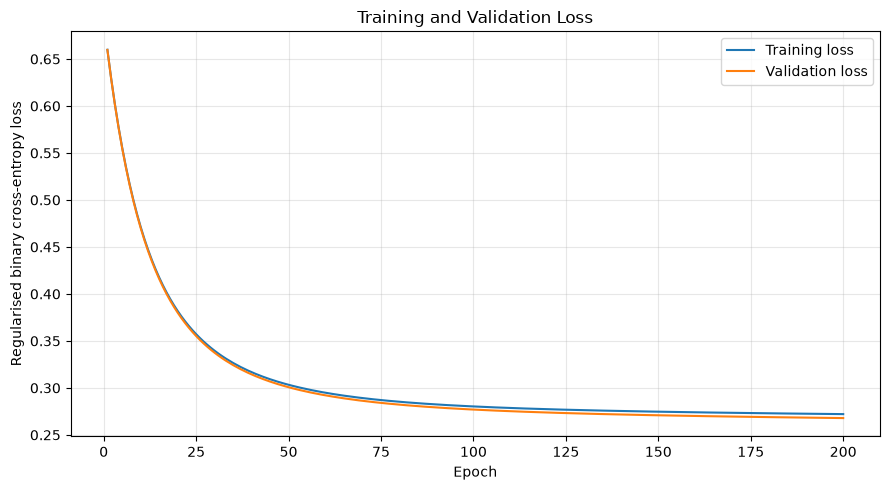

Loss history summary:
 epoch  training_loss  validation_loss
   191       0.272489         0.268332
   192       0.272446         0.268283
   193       0.272404         0.268233
   194       0.272362         0.268184
   195       0.272321         0.268136
   196       0.272279         0.268087
   197       0.272238         0.268040
   198       0.272198         0.267992
   199       0.272158         0.267945
   200       0.272118         0.267899

Best validation loss: 0.26790 at epoch 200


In [51]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["training_loss"],
    label="Training loss"
)
plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Regularised binary cross-entropy loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Loss history summary:")
print(history_df.tail(10).to_string(index=False))

print(
    f"\nBest validation loss: {best_validation_loss:.5f} "
    f"at epoch {best_epoch}"
)

### 6.32 Interpretation of Model Coefficients

The coefficient analysis identified page count and author count as positive numerical associations with the model's predicted odds of an observed NYT match. The coefficient for standardised page count was 0.1824, corresponding to an odds ratio of approximately 1.20 per standard deviation increase, holding other features constant. The author count coefficient was 0.0794, with an odds ratio of approximately 1.08.

The strongest negative coefficients included `publisher_Other` and `format_Paperback`. Their odds ratios were approximately 0.36 and 0.46, respectively, relative to the relevant reference categories. These results describe the model's learned associations in this dataset. They do not establish that particular formats or publishers cause higher or lower bestseller performance.

Categorical coefficients depend on the encoding and reference category. The results must also be interpreted in light of the sampled class distribution and the definition of the target as observed NYT ISBN membership.

### 6.33 Interpretation of the Learning Curve

Training and validation loss decreased consistently over the 200 epochs. The curves remained close together, and the validation loss did not show a clear upward trend. This provides no obvious evidence of overfitting during the observed training period.

The best validation loss was 0.26790 at epoch 200, which was also the final epoch. Because validation loss was still decreasing, the training run reached its predefined epoch limit before early stopping was triggered. Further training could be investigated using validation performance, while keeping the original test results clearly distinguished from any later experiment.

### 6.34 Extended Training Experiment

The initial logistic regression model was trained for 200 epochs. The validation loss was still decreasing at the end of this run, suggesting that further optimisation may be beneficial.

A separate extended training experiment will therefore be conducted for up to 500 epochs. The same feature matrices, learning rate and L2 regularisation strength will be retained to isolate the effect of additional training. Early stopping will use validation loss with a patience of 30 epochs.

The best parameter values from the extended run will be retained. The resulting model will be compared with the original baseline using validation loss, ROC AUC, average precision, precision, recall and F1 score. The original model's results will be preserved for transparent comparison.

Epoch   1 | Training loss: 0.27208 | Validation loss: 0.26785
Epoch  25 | Training loss: 0.27121 | Validation loss: 0.26683
Epoch  50 | Training loss: 0.27044 | Validation loss: 0.26592
Epoch  75 | Training loss: 0.26976 | Validation loss: 0.26512
Epoch 100 | Training loss: 0.26915 | Validation loss: 0.26440
Epoch 125 | Training loss: 0.26860 | Validation loss: 0.26375
Epoch 150 | Training loss: 0.26809 | Validation loss: 0.26316
Epoch 175 | Training loss: 0.26762 | Validation loss: 0.26262
Epoch 200 | Training loss: 0.26719 | Validation loss: 0.26213
Epoch 225 | Training loss: 0.26679 | Validation loss: 0.26166
Epoch 250 | Training loss: 0.26641 | Validation loss: 0.26123
Epoch 275 | Training loss: 0.26605 | Validation loss: 0.26083
Epoch 300 | Training loss: 0.26571 | Validation loss: 0.26045
Epoch 325 | Training loss: 0.26539 | Validation loss: 0.26010
Epoch 350 | Training loss: 0.26509 | Validation loss: 0.25976
Epoch 375 | Training loss: 0.26480 | Validation loss: 0.25944
Epoch 40

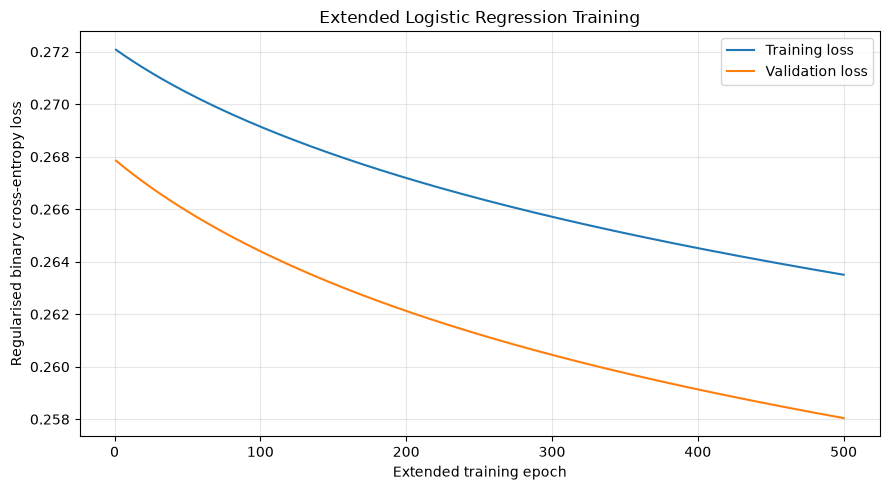

In [52]:
import time
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Preserve the original baseline
# --------------------------------------------------

baseline_weights = weights.copy()
baseline_bias = float(bias)
baseline_best_epoch = best_epoch
baseline_validation_loss = float(best_validation_loss)

# --------------------------------------------------
# 2. Configure the extended experiment
# --------------------------------------------------

learning_rate_extended = 0.1
max_epochs_extended = 500
l2_strength_extended = 0.001
patience_extended = 30
minimum_improvement_extended = 1e-5

n_samples = X_train_scaled.shape[0]
n_features = X_train_scaled.shape[1]

# Start from the original model's best parameters.
extended_weights = baseline_weights.copy()
extended_bias = baseline_bias

best_extended_weights = extended_weights.copy()
best_extended_bias = extended_bias
best_extended_validation_loss = float("inf")
best_extended_epoch = 0
epochs_without_improvement = 0

extended_history = []
start_time = time.time()

# --------------------------------------------------
# 3. Extended gradient descent
# --------------------------------------------------

for epoch in range(1, max_epochs_extended + 1):

    # Forward pass.
    train_probabilities = sigmoid(
        X_train_scaled @ extended_weights + extended_bias
    )

    errors = train_probabilities - y_train

    # Gradient for coefficients.
    weight_gradient = (
        X_train_scaled.T @ errors
    ) / n_samples

    weight_gradient += (
        l2_strength_extended / n_samples
    ) * extended_weights

    # Gradient for the intercept.
    bias_gradient = np.mean(errors)

    # Update parameters.
    extended_weights -= (
        learning_rate_extended * weight_gradient
    )
    extended_bias -= (
        learning_rate_extended * bias_gradient
    )

    # Calculate losses after the update.
    train_loss = logistic_loss(
        X_train_scaled,
        y_train,
        extended_weights,
        extended_bias,
        l2_strength_extended
    )

    validation_loss = logistic_loss(
        X_validation_scaled,
        y_validation,
        extended_weights,
        extended_bias,
        l2_strength_extended
    )

    extended_history.append({
        "epoch": epoch,
        "training_loss": train_loss,
        "validation_loss": validation_loss
    })

    # Retain the best parameters based on validation loss.
    if (
        validation_loss
        < best_extended_validation_loss - minimum_improvement_extended
    ):
        best_extended_validation_loss = validation_loss
        best_extended_weights = extended_weights.copy()
        best_extended_bias = extended_bias
        best_extended_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Training loss: {train_loss:.5f} | "
            f"Validation loss: {validation_loss:.5f}"
        )

    if epochs_without_improvement >= patience_extended:
        print(
            f"\nEarly stopping triggered at epoch {epoch}; "
            f"no sufficient validation-loss improvement for "
            f"{patience_extended} consecutive epochs."
        )
        break

extended_elapsed_time = time.time() - start_time

# --------------------------------------------------
# 4. Retain the best extended model separately
# --------------------------------------------------

extended_weights_final = best_extended_weights.copy()
extended_bias_final = float(best_extended_bias)

extended_history_df = pd.DataFrame(extended_history)

print("\nExtended training complete")
print(f"Epochs run: {len(extended_history_df)}")
print(f"Best epoch: {best_extended_epoch}")
print(f"Best validation loss: {best_extended_validation_loss:.6f}")
print(f"Training time: {extended_elapsed_time:.2f} seconds")

# --------------------------------------------------
# 5. Compare baseline and extended validation loss
# --------------------------------------------------

comparison = pd.DataFrame([
    {
        "model": "Baseline",
        "best_epoch": baseline_best_epoch,
        "best_validation_loss": baseline_validation_loss
    },
    {
        "model": "Extended",
        "best_epoch": best_extended_epoch,
        "best_validation_loss": best_extended_validation_loss
    }
])

print("\nValidation loss comparison:")
print(comparison.to_string(index=False))

# Plot the extended training curve.
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(
    extended_history_df["epoch"],
    extended_history_df["training_loss"],
    label="Training loss"
)
plt.plot(
    extended_history_df["epoch"],
    extended_history_df["validation_loss"],
    label="Validation loss"
)
plt.xlabel("Extended training epoch")
plt.ylabel("Regularised binary cross-entropy loss")
plt.title("Extended Logistic Regression Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_validation_model(model_weights, model_bias, threshold=0.17):
    probabilities = sigmoid(
        X_validation_scaled @ model_weights + model_bias
    )
    predictions = (probabilities >= threshold).astype(int)

    return {
        "threshold": threshold,
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_validation, probabilities
        ),
        "average_precision": average_precision_score(
            y_validation, probabilities
        ),
        "predicted_positive_count": int(predictions.sum())
    }

baseline_validation_metrics = evaluate_validation_model(
    baseline_weights, baseline_bias
)

extended_validation_metrics = evaluate_validation_model(
    extended_weights_final, extended_bias_final
)

validation_comparison = pd.DataFrame([
    {"model": "Baseline", **baseline_validation_metrics},
    {"model": "Extended", **extended_validation_metrics}
])

print(validation_comparison.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}"
))

   model  threshold  precision  recall     f1  roc_auc  average_precision  predicted_positive_count
Baseline     0.1700     0.3080  0.3871 0.3431   0.7773             0.2876                      1146
Extended     0.1700     0.3182  0.3925 0.3515   0.7905             0.3189                      1125


In [54]:
# Preserve the 500-epoch model and its validation results.
model_500_weights = extended_weights_final.copy()
model_500_bias = float(extended_bias_final)

model_500_validation_loss = float(
    best_extended_validation_loss
)
model_500_best_epoch = int(best_extended_epoch)

model_500_validation_metrics = (
    extended_validation_metrics.copy()
)

print("Extended model checkpoint saved in notebook memory.")
print("Best epoch:", model_500_best_epoch)
print(
    "Best validation loss:",
    f"{model_500_validation_loss:.6f}"
)
print(
    "Validation F1:",
    f"{model_500_validation_metrics['f1']:.4f}"
)
print(
    "Validation ROC AUC:",
    f"{model_500_validation_metrics['roc_auc']:.4f}"
)
print(
    "Validation average precision:",
    f"{model_500_validation_metrics['average_precision']:.4f}"
)

Extended model checkpoint saved in notebook memory.
Best epoch: 500
Best validation loss: 0.258043
Validation F1: 0.3515
Validation ROC AUC: 0.7905
Validation average precision: 0.3189


### 6.35 Final Extended Training Experiment

The 500 epoch experiment improved validation loss, F1 score, ROC AUC and average precision compared with the original 200 epoch baseline. However, validation loss was still decreasing at the end of the extended run.

A further experiment will therefore start from the saved 500 epoch checkpoint and allow up to 1,000 additional epochs. The learning rate and L2 regularisation strength will remain unchanged. Validation loss will be monitored with a patience of 50 epochs, and the parameters producing the lowest validation loss will be retained.

This experiment will assess whether additional optimisation provides further benefits. The comparison will use the same validation dataset and decision threshold initially, separating the effect of training duration from the effect of threshold selection. The held out test set will not be used to select the model or training duration.

Starting from the saved 500-epoch checkpoint.
Checkpoint validation loss: 0.258043
Additional epoch    1 | Training loss: 0.263496 | Validation loss: 0.258033
Additional epoch  100 | Training loss: 0.262611 | Validation loss: 0.257098
Additional epoch  200 | Training loss: 0.261800 | Validation loss: 0.256254
Additional epoch  300 | Training loss: 0.261050 | Validation loss: 0.255483
Additional epoch  400 | Training loss: 0.260347 | Validation loss: 0.254766
Additional epoch  500 | Training loss: 0.259679 | Validation loss: 0.254093
Additional epoch  600 | Training loss: 0.259041 | Validation loss: 0.253454
Additional epoch  700 | Training loss: 0.258428 | Validation loss: 0.252843
Additional epoch  800 | Training loss: 0.257837 | Validation loss: 0.252258
Additional epoch  900 | Training loss: 0.257266 | Validation loss: 0.251694
Additional epoch 1000 | Training loss: 0.256711 | Validation loss: 0.251149

Final extended experiment complete.
Additional epochs run: 1000
Best additional 

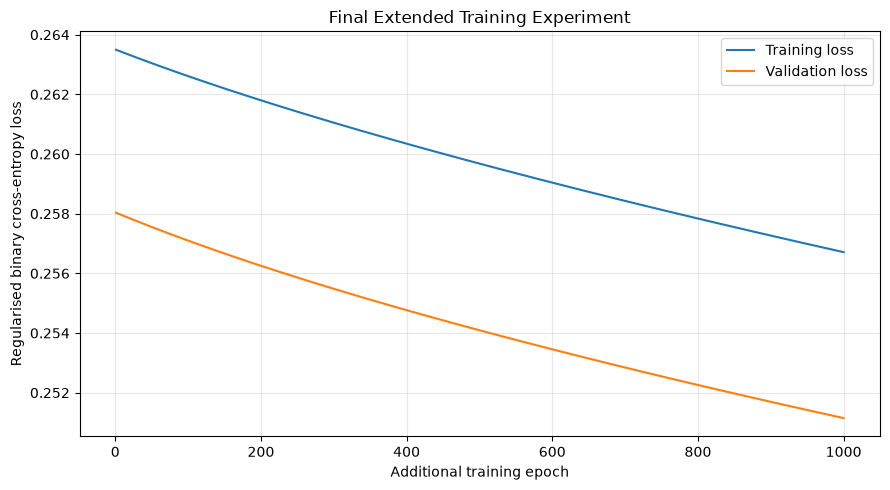

In [55]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Verify and preserve the 500-epoch checkpoint
# --------------------------------------------------

weights_500 = model_500_weights.copy()
bias_500 = float(model_500_bias)

assert weights_500.shape == (X_train_scaled.shape[1],)
assert X_train_scaled.shape[1] == X_validation_scaled.shape[1]

print("Starting from the saved 500-epoch checkpoint.")
print(f"Checkpoint validation loss: {model_500_validation_loss:.6f}")

# --------------------------------------------------
# 2. Configure final extended training
# --------------------------------------------------

learning_rate_final = 0.1
max_additional_epochs = 1000
l2_strength_final = 0.001
patience_final = 50
minimum_improvement_final = 1e-5

n_samples = X_train_scaled.shape[0]

weights_final_run = weights_500.copy()
bias_final_run = bias_500

best_weights_final_run = weights_final_run.copy()
best_bias_final_run = bias_final_run

best_validation_loss_final_run = model_500_validation_loss
best_epoch_final_run = 0
epochs_without_improvement = 0

final_extended_history = []

start_time = time.time()

# --------------------------------------------------
# 3. Continue gradient descent
# --------------------------------------------------

for epoch in range(1, max_additional_epochs + 1):

    probabilities = sigmoid(
        X_train_scaled @ weights_final_run + bias_final_run
    )

    errors = probabilities - y_train

    weight_gradient = (
        X_train_scaled.T @ errors
    ) / n_samples

    weight_gradient += (
        l2_strength_final / n_samples
    ) * weights_final_run

    bias_gradient = np.mean(errors)

    weights_final_run -= (
        learning_rate_final * weight_gradient
    )
    bias_final_run -= (
        learning_rate_final * bias_gradient
    )

    train_loss = logistic_loss(
        X_train_scaled,
        y_train,
        weights_final_run,
        bias_final_run,
        l2_strength_final
    )

    validation_loss = logistic_loss(
        X_validation_scaled,
        y_validation,
        weights_final_run,
        bias_final_run,
        l2_strength_final
    )

    final_extended_history.append({
        "additional_epoch": epoch,
        "training_loss": train_loss,
        "validation_loss": validation_loss
    })

    # Compare against the best validation loss from the
    # original 500-epoch experiment as well.
    if (
        validation_loss
        < best_validation_loss_final_run - minimum_improvement_final
    ):
        best_validation_loss_final_run = validation_loss
        best_weights_final_run = weights_final_run.copy()
        best_bias_final_run = bias_final_run
        best_epoch_final_run = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 100 == 0:
        print(
            f"Additional epoch {epoch:4d} | "
            f"Training loss: {train_loss:.6f} | "
            f"Validation loss: {validation_loss:.6f}"
        )

    if epochs_without_improvement >= patience_final:
        print(
            f"\nEarly stopping at additional epoch {epoch}: "
            f"validation loss did not improve sufficiently "
            f"for {patience_final} consecutive epochs."
        )
        break

final_extended_elapsed = time.time() - start_time
final_extended_history_df = pd.DataFrame(final_extended_history)

# --------------------------------------------------
# 4. Save the best model separately
# --------------------------------------------------

model_final_weights = best_weights_final_run.copy()
model_final_bias = float(best_bias_final_run)
model_final_validation_loss = float(best_validation_loss_final_run)

print("\nFinal extended experiment complete.")
print(f"Additional epochs run: {len(final_extended_history_df)}")
print(f"Best additional epoch: {best_epoch_final_run}")
print(f"Best validation loss: {model_final_validation_loss:.6f}")
print(f"Elapsed time: {final_extended_elapsed:.2f} seconds")

print("\nValidation loss comparison:")
print(f"200-epoch baseline: {baseline_validation_loss:.6f}")
print(f"500-epoch checkpoint: {model_500_validation_loss:.6f}")
print(f"Final extended model: {model_final_validation_loss:.6f}")

# --------------------------------------------------
# 5. Plot the additional training history
# --------------------------------------------------

plt.figure(figsize=(9, 5))
plt.plot(
    final_extended_history_df["additional_epoch"],
    final_extended_history_df["training_loss"],
    label="Training loss"
)
plt.plot(
    final_extended_history_df["additional_epoch"],
    final_extended_history_df["validation_loss"],
    label="Validation loss"
)
plt.xlabel("Additional training epoch")
plt.ylabel("Regularised binary cross-entropy loss")
plt.title("Final Extended Training Experiment")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
# Compare all three saved models on the same validation set
# using the same threshold of 0.17.

validation_model_comparison = []

models_to_compare = [
    ("Baseline 200 epochs", baseline_weights, baseline_bias),
    ("Extended 500 epochs", model_500_weights, model_500_bias),
    ("Final extended", model_final_weights, model_final_bias)
]

for model_name, model_weights, model_bias in models_to_compare:
    metrics = evaluate_validation_model(
        model_weights,
        model_bias,
        threshold=0.17
    )

    validation_model_comparison.append({
        "model": model_name,
        "validation_loss": logistic_loss(
            X_validation_scaled,
            y_validation,
            model_weights,
            model_bias,
            0.001
        ),
        **metrics
    })

validation_model_comparison_df = pd.DataFrame(
    validation_model_comparison
)

print(
    validation_model_comparison_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

              model  validation_loss  threshold  precision  recall     f1  roc_auc  average_precision  predicted_positive_count
Baseline 200 epochs           0.2679     0.1700     0.3080  0.3871 0.3431   0.7773             0.2876                      1146
Extended 500 epochs           0.2580     0.1700     0.3182  0.3925 0.3515   0.7905             0.3189                      1125
     Final extended           0.2512     0.1700     0.3500  0.4386 0.3893   0.8048             0.3656                      1143


### 6.36 Results of the Final Extended Training Experiment

The final extended training experiment continued from the saved 500 epoch checkpoint for a further 1,000 epochs. The training and validation losses continued to decrease, with the best recorded validation loss reaching 0.251154 at additional epoch 999. The experiment reached its maximum epoch limit, so convergence was not conclusively established.

At the unchanged decision threshold of 0.17, the final extended model achieved validation precision of 35.00%, recall of 43.86%, an F1 score of 0.3893, ROC AUC of 0.8048 and average precision of 0.3656. These results improved on both the original 200 epoch baseline and the 500 epoch checkpoint.

The final extended model is retained as the leading candidate because it achieved the strongest validation results among the three experiments. The results suggest that further optimisation improved the model's ability to distinguish observed NYT matches from records without an observed match. However, the results remain specific to the sampled dataset and its target definition, and should not be interpreted as proof of universal bestseller prediction ability.

### 6.37 Decision Threshold Selection for the Final Extended Model

The final extended model achieved improved validation performance compared with the earlier experiments. However, the probability threshold of 0.17 was selected using the baseline model and may not be optimal for the final model.

The decision threshold will therefore be reassessed using the final extended model's validation probabilities. Thresholds will be compared using precision, recall and F1 score. The threshold with the highest validation F1 score among the tested values will be selected for the final model.

The test set will not be used to select this threshold. The selected threshold and its validation metrics will be recorded before any further test evaluation.

In [57]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# 1. Calculate probabilities on the validation set
# --------------------------------------------------

final_validation_probabilities = sigmoid(
    X_validation_scaled @ model_final_weights
    + model_final_bias
)

# --------------------------------------------------
# 2. Compare candidate thresholds
# --------------------------------------------------

candidate_thresholds = np.round(
    np.arange(0.02, 0.501, 0.01),
    3
)

final_threshold_results = []

for threshold in candidate_thresholds:
    predictions = (
        final_validation_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    final_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "predicted_positives": int(predictions.sum())
    })

final_threshold_df = pd.DataFrame(final_threshold_results)

# --------------------------------------------------
# 3. Identify the threshold with the highest F1 score
# --------------------------------------------------

final_threshold_df = final_threshold_df.sort_values(
    ["f1", "recall", "precision"],
    ascending=[False, False, False]
).reset_index(drop=True)

print("Top 15 thresholds by validation F1 score:")
print(
    final_threshold_df.head(15).to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

best_final_threshold_row = final_threshold_df.iloc[0]

final_model_threshold = float(
    best_final_threshold_row["threshold"]
)

print("\nSelected threshold for the final extended model")
print(f"Threshold: {final_model_threshold:.3f}")
print(f"Precision: {best_final_threshold_row['precision']:.4f}")
print(f"Recall: {best_final_threshold_row['recall']:.4f}")
print(f"F1 score: {best_final_threshold_row['f1']:.4f}")
print(
    "True positives:",
    int(best_final_threshold_row["true_positives"])
)
print(
    "False positives:",
    int(best_final_threshold_row["false_positives"])
)
print(
    "False negatives:",
    int(best_final_threshold_row["false_negatives"])
)
print(
    "Predicted positives:",
    int(best_final_threshold_row["predicted_positives"])
)

Top 15 thresholds by validation F1 score:
 threshold  precision  recall     f1  true_positives  false_positives  false_negatives  predicted_positives
    0.1600     0.3442  0.4748 0.3991             433              825              479                 1258
    0.1500     0.3331  0.4912 0.3970             448              897              464                 1345
    0.1700     0.3500  0.4386 0.3893             400              743              512                 1143
    0.2000     0.3988  0.3739 0.3860             341              514              571                  855
    0.1900     0.3819  0.3849 0.3834             351              568              561                  919
    0.2100     0.4047  0.3607 0.3814             329              484              583                  813
    0.1400     0.3009  0.5186 0.3808             473             1099              439                 1572
    0.1800     0.3596  0.4046 0.3808             369              657              543        

### 6.38 Final Decision Threshold

The final extended logistic regression model was evaluated across candidate decision thresholds using the validation set. The threshold of 0.16 produced the highest F1 score among the tested values, achieving precision of 34.42%, recall of 47.48% and an F1 score of 0.3991.

At this threshold, the model identified 433 positive records, generated 825 false positives and missed 479 positive records in the validation set. The threshold of 0.16 was selected for the final extended model because it provided the strongest observed balance between precision and recall according to the F1 score among the thresholds evaluated.

The threshold was selected exclusively from validation results. The test set was not used to choose it. As the negative class consists of records without an observed ISBN match in the selected NYT records, these metrics evaluate the defined matching task rather than definitive bestseller status.

In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict using the final extended model.
final_test_probabilities = sigmoid(
    X_test_scaled @ model_final_weights + model_final_bias
)

final_test_predictions = (
    final_test_probabilities >= final_model_threshold
).astype(int)

# Calculate final follow-up test metrics.
final_test_metrics = {
    "Threshold": final_model_threshold,
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Precision": precision_score(
        y_test, final_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_test_predictions, zero_division=0
    ),
    "F1 score": f1_score(
        y_test, final_test_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(
        y_test, final_test_probabilities
    ),
    "Average precision": average_precision_score(
        y_test, final_test_probabilities
    )
}

print("FINAL EXTENDED MODEL: FOLLOW-UP TEST EVALUATION")
for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_test,
        final_test_predictions,
        labels=[0, 1]
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        labels=[0, 1],
        target_names=[
            "No observed NYT match",
            "Observed NYT match"
        ],
        zero_division=0,
        digits=4
    )
)

FINAL EXTENDED MODEL: FOLLOW-UP TEST EVALUATION
Threshold: 0.1600
Accuracy: 0.8716
Precision: 0.3431
Recall: 0.4516
F1 score: 0.3899
ROC AUC: 0.7903
Average precision: 0.3353

Confusion matrix:
[[8321  787]
 [ 499  411]]

Classification report:
                       precision    recall  f1-score   support

No observed NYT match     0.9434    0.9136    0.9283      9108
   Observed NYT match     0.3431    0.4516    0.3899       910

             accuracy                         0.8716     10018
            macro avg     0.6432    0.6826    0.6591     10018
         weighted avg     0.8889    0.8716    0.8794     10018



### 6.39 Feature Ablation Experiment

Feature ablation is used to investigate the contribution of different predictor groups to the logistic regression model's validation performance. Rather than assuming that every selected feature improves classification, separate models are trained using different combinations of numerical and categorical predictors.

The experiments compare the full feature set with numerical features only, categorical features only, and models that exclude publisher or format information. All variants use the same training and validation records and the same optimisation settings to support a fair comparison.

The comparison focuses on validation average precision, ROC AUC and F1 score. Average precision is particularly relevant because the positive class is less frequent than the negative class. F1 is calculated using a fixed threshold of 0.16 for these comparisons, rather than optimising a separate threshold for every variant. This keeps the classification threshold consistent, although it does not guarantee that 0.16 is optimal for every model.

The experiment is intended to assess the predictive contribution of feature groups in the constructed dataset. Results are interpreted as associations with observed NYT ISBN matching, not as evidence of causal relationships or definitive commercial bestseller status.

In [59]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# 1. Define a reusable from-scratch training function
# --------------------------------------------------

def fit_logistic_from_scratch(
    X_train_input,
    y_train_input,
    X_validation_input,
    y_validation_input,
    learning_rate=0.1,
    epochs=500,
    l2_strength=0.001,
    patience=50,
    minimum_improvement=1e-5
):
    """
    Train logistic regression from scratch using gradient descent.
    Retain the weights with the lowest validation loss.
    """

    weights_local = np.zeros(
        X_train_input.shape[1],
        dtype=np.float64
    )
    bias_local = 0.0

    best_weights_local = weights_local.copy()
    best_bias_local = bias_local
    best_validation_loss_local = float("inf")
    best_epoch_local = 0
    no_improvement = 0

    history_local = []

    n_samples = X_train_input.shape[0]

    for epoch in range(1, epochs + 1):

        # Forward pass on training data.
        probabilities = sigmoid(
            X_train_input @ weights_local + bias_local
        )

        # Calculate gradients.
        errors = probabilities - y_train_input

        weight_gradient = (
            X_train_input.T @ errors
        ) / n_samples

        weight_gradient += (
            l2_strength / n_samples
        ) * weights_local

        bias_gradient = np.mean(errors)

        # Gradient descent update.
        weights_local -= learning_rate * weight_gradient
        bias_local -= learning_rate * bias_gradient

        # Evaluate the updated model.
        training_loss_local = logistic_loss(
            X_train_input,
            y_train_input,
            weights_local,
            bias_local,
            l2_strength
        )

        validation_loss_local = logistic_loss(
            X_validation_input,
            y_validation_input,
            weights_local,
            bias_local,
            l2_strength
        )

        history_local.append({
            "epoch": epoch,
            "training_loss": training_loss_local,
            "validation_loss": validation_loss_local
        })

        # Preserve the best validation checkpoint.
        if (
            validation_loss_local
            < best_validation_loss_local - minimum_improvement
        ):
            best_validation_loss_local = validation_loss_local
            best_weights_local = weights_local.copy()
            best_bias_local = float(bias_local)
            best_epoch_local = epoch
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= patience:
            break

    return {
        "weights": best_weights_local,
        "bias": best_bias_local,
        "best_validation_loss": best_validation_loss_local,
        "best_epoch": best_epoch_local,
        "history": pd.DataFrame(history_local)
    }


# --------------------------------------------------
# 2. Identify feature groups from existing feature names
# --------------------------------------------------

numeric_names = {
    "publication_year",
    "num_pages_clean",
    "author_count"
}

feature_names_array = np.array(feature_names, dtype=str)

numeric_mask = np.array([
    name in numeric_names
    for name in feature_names_array
])

format_mask = np.array([
    name.startswith("format_")
    for name in feature_names_array
])

publisher_mask = np.array([
    name.startswith("publisher_")
    for name in feature_names_array
])

ebook_mask = np.array([
    name == "is_ebook"
    for name in feature_names_array
])

categorical_mask = format_mask | publisher_mask | ebook_mask

# Confirm that every feature has been assigned to a group.
assert np.all(numeric_mask | categorical_mask)
assert np.all(numeric_mask | format_mask | publisher_mask | ebook_mask)

feature_groups = {
    "Full model": np.ones(len(feature_names), dtype=bool),
    "Numerical only": numeric_mask,
    "Categorical only": categorical_mask,
    "Without publisher": ~publisher_mask,
    "Without format": ~format_mask
}

print("Number of features in each experiment:")
for name, mask in feature_groups.items():
    print(f"{name}: {int(mask.sum())}")


# --------------------------------------------------
# 3. Train and evaluate each feature configuration
# --------------------------------------------------

ABLATION_THRESHOLD = 0.16

ablation_results = []
ablation_models = {}

for experiment_name, feature_mask in feature_groups.items():

    if feature_mask.sum() == 0:
        print(f"Skipping {experiment_name}: no features selected.")
        continue

    X_train_variant = X_train_scaled[:, feature_mask]
    X_validation_variant = X_validation_scaled[:, feature_mask]

    model_variant = fit_logistic_from_scratch(
        X_train_variant,
        y_train,
        X_validation_variant,
        y_validation,
        learning_rate=0.1,
        epochs=500,
        l2_strength=0.001,
        patience=50,
        minimum_improvement=1e-5
    )

    validation_probabilities_variant = sigmoid(
        X_validation_variant @ model_variant["weights"]
        + model_variant["bias"]
    )

    validation_predictions_variant = (
        validation_probabilities_variant >= ABLATION_THRESHOLD
    ).astype(int)

    ablation_results.append({
        "experiment": experiment_name,
        "feature_count": int(feature_mask.sum()),
        "best_epoch": model_variant["best_epoch"],
        "validation_loss": model_variant["best_validation_loss"],
        "average_precision": average_precision_score(
            y_validation,
            validation_probabilities_variant
        ),
        "roc_auc": roc_auc_score(
            y_validation,
            validation_probabilities_variant
        ),
        "precision": precision_score(
            y_validation,
            validation_predictions_variant,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            validation_predictions_variant,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation,
            validation_predictions_variant,
            zero_division=0
        )
    })

    ablation_models[experiment_name] = {
        **model_variant,
        "feature_mask": feature_mask.copy(),
        "validation_probabilities": validation_probabilities_variant
    }

ablation_results_df = pd.DataFrame(ablation_results)

ablation_results_df = ablation_results_df.sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

print("\nFeature ablation results:")
print(
    ablation_results_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)


Number of features in each experiment:
Full model: 123
Numerical only: 3
Categorical only: 120
Without publisher: 15
Without format: 112

Feature ablation results:
       experiment  feature_count  best_epoch  validation_loss  average_precision  roc_auc  precision  recall     f1
 Categorical only            120         500           0.2648             0.3605   0.7833     0.2752  0.3893 0.3224
       Full model            123         500           0.2605             0.3077   0.7870     0.2944  0.4013 0.3397
   Without format            112         499           0.2737             0.2771   0.7514     0.2733  0.5526 0.3657
Without publisher             15         500           0.2849             0.1966   0.6960     0.2425  0.3202 0.2760
   Numerical only              3         495           0.2991             0.1415   0.6358     0.2114  0.0285 0.0502


**Interpretation of Feature Ablation Results**

The feature ablation experiment indicates that the categorical only model achieved the strongest validation performance, with an average precision of 0.3605 and a ROC AUC of 0.7833. It also achieved an F1 score of 0.3224 at the fixed decision threshold of 0.16. The full model achieved an average precision of 0.3077, a ROC AUC of 0.7870 and an F1 score of 0.3397.

The categorical only model achieved higher average precision than the full model, suggesting that the categorical predictors contain useful information for ranking records according to observed NYT ISBN matching. However, the full model achieved a slightly higher ROC AUC and F1 score, indicating that the preferred feature configuration depends on the evaluation metric. The categorical only model's precision was also higher, while its recall was lower than that of the full model.

Removing publisher features reduced average precision to 0.1966, while removing format reduced it to 0.2771. These results suggest that publisher and format information contribute to the model's ranking performance, particularly publisher information within this experiment. The numerical only model performed weakest, with average precision of 0.1415 and a ROC AUC of 0.6358, indicating that publication year, page count and author count alone provide limited discrimination in this dataset.

Overall, the experiment suggests that categorical information is important for identifying observed NYT matches. However, the results do not establish causal relationships, and the performance of the categorical only model should be confirmed under consistent extended training settings before it is selected as the final configuration. All comparisons are based on the sampled dataset and its observed matching target.

### 6.40 L2 Regularisation Sensitivity Analysis

L2 regularisation penalises large model coefficients and can help control overfitting. The current model uses a regularisation strength of 0.001, but this value may not be optimal for the selected features and sampled dataset.

A sensitivity experiment is therefore conducted using several regularisation strengths while keeping the training and validation subsets, predictors, learning rate and maximum training duration consistent. Each model is trained from scratch, and the checkpoint with the lowest validation loss is retained.

The models are compared using validation loss, average precision, ROC AUC and F1 score at the fixed decision threshold of 0.16. The results are used to assess how regularisation influences predictive performance and coefficient complexity. The experiment does not assume that increasing regularisation will necessarily improve the model.

L2 regularisation sensitivity results:
 l2_strength  best_epoch  validation_loss  average_precision  roc_auc  precision  recall     f1  coefficient_l2_norm
      0.0000         500           0.2605             0.3077   0.7870     0.2944  0.4013 0.3397               1.6234
      0.0001         500           0.2605             0.3077   0.7870     0.2944  0.4013 0.3397               1.6234
      0.0010         500           0.2605             0.3077   0.7870     0.2944  0.4013 0.3397               1.6234
      0.0100         500           0.2605             0.3077   0.7870     0.2944  0.4013 0.3397               1.6234
      0.1000         500           0.2605             0.3076   0.7870     0.2944  0.4013 0.3397               1.6234


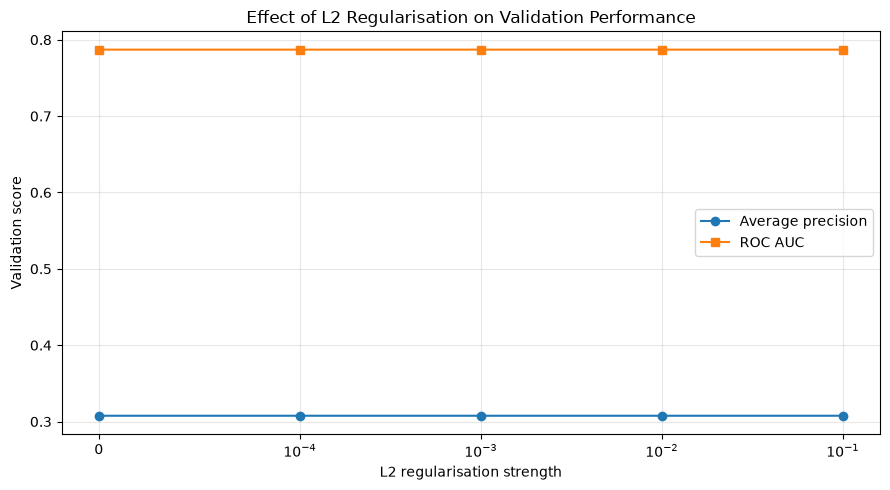

In [60]:

# --------------------------------------------------
# 1. Define regularisation strengths to compare
# --------------------------------------------------

regularisation_strengths = [
    0.0,
    0.0001,
    0.001,
    0.01,
    0.1
]

REGULARISATION_THRESHOLD = 0.16

regularisation_results = []
regularisation_models = {}

# --------------------------------------------------
# 2. Train each model from scratch
# --------------------------------------------------

for strength in regularisation_strengths:

    model_regularised = fit_logistic_from_scratch(
        X_train_scaled,
        y_train,
        X_validation_scaled,
        y_validation,
        learning_rate=0.1,
        epochs=500,
        l2_strength=strength,
        patience=50,
        minimum_improvement=1e-5
    )

    probabilities_regularised = sigmoid(
        X_validation_scaled @ model_regularised["weights"]
        + model_regularised["bias"]
    )

    predictions_regularised = (
        probabilities_regularised >= REGULARISATION_THRESHOLD
    ).astype(int)

    # Calculate the size of the learned coefficient vector.
    coefficient_l2_norm = float(
        np.linalg.norm(model_regularised["weights"], ord=2)
    )

    regularisation_results.append({
        "l2_strength": strength,
        "best_epoch": model_regularised["best_epoch"],
        "validation_loss": model_regularised["best_validation_loss"],
        "average_precision": average_precision_score(
            y_validation,
            probabilities_regularised
        ),
        "roc_auc": roc_auc_score(
            y_validation,
            probabilities_regularised
        ),
        "precision": precision_score(
            y_validation,
            predictions_regularised,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions_regularised,
            zero_division=0
        ),
        "f1": f1_score(
            y_validation,
            predictions_regularised,
            zero_division=0
        ),
        "coefficient_l2_norm": coefficient_l2_norm
    })

    regularisation_models[strength] = {
        **model_regularised,
        "validation_probabilities": probabilities_regularised
    }

regularisation_results_df = pd.DataFrame(regularisation_results)

print("L2 regularisation sensitivity results:")
print(
    regularisation_results_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)


# --------------------------------------------------
# 3. Plot regularisation strength against performance
# --------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    regularisation_results_df["l2_strength"],
    regularisation_results_df["average_precision"],
    marker="o",
    label="Average precision"
)

plt.plot(
    regularisation_results_df["l2_strength"],
    regularisation_results_df["roc_auc"],
    marker="s",
    label="ROC AUC"
)

plt.xscale("symlog", linthresh=0.0001)
plt.xlabel("L2 regularisation strength")
plt.ylabel("Validation score")
plt.title("Effect of L2 Regularisation on Validation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation of L2 Regularisation Results**

The L2 sensitivity experiment compared regularisation strengths ranging from 0 to 0.1. The validation loss, average precision, ROC AUC, precision, recall, F1 score and coefficient L2 norm remained effectively unchanged across the tested settings. Average precision remained approximately 0.3077, ROC AUC remained approximately 0.7870, and the coefficient norm remained approximately 1.6234.

These results indicate that changing the L2 strength within the tested range did not produce a meaningful change in the model's observed validation performance. The results do not demonstrate that stronger regularisation improves generalisation, nor do they establish that regularisation is unnecessary. The coefficients and predictions may simply be relatively insensitive to the tested penalty values under the current optimisation settings.

The experiment therefore provides no strong evidence for replacing the existing regularisation setting on the basis of predictive performance alone. Further investigation would be needed to establish whether different optimisation settings, more extensive training or a wider regularisation range produce meaningful differences.

### 6.41 Precision Recall Curve Analysis

The precision recall curve evaluates the relationship between precision and recall across classification thresholds. This is particularly useful for the current task because the positive class represents a minority of the sampled records.

The curve is compared with a baseline corresponding to the observed positive class proportion in the validation set. Average precision is also calculated to summarise the precision recall trade off across thresholds. The selected threshold of 0.16 is marked on the curve to show its operating point.

The curve helps explain why the decision threshold matters: lowering the threshold generally identifies more positive records but may increase false positives, while raising it generally reduces predicted positives and may miss more observed matches. These results assess classification of the constructed target rather than definitive bestseller status.

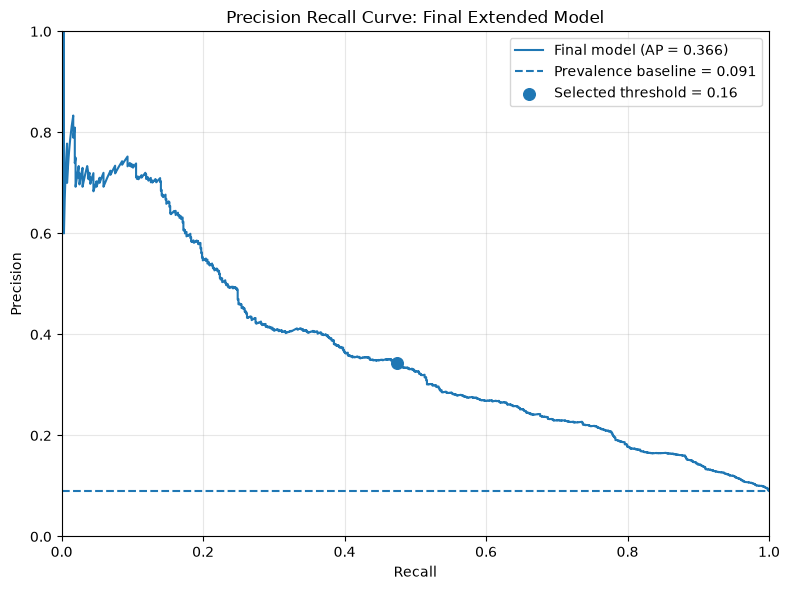

Validation positive prevalence: 0.0910
Validation average precision: 0.3656
Selected threshold: 0.160
Precision at selected threshold: 0.3442
Recall at selected threshold: 0.4748


In [61]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# --------------------------------------------------
# 1. Calculate precision and recall across thresholds
# --------------------------------------------------

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_validation,
        final_validation_probabilities
    )
)

validation_prevalence = float(np.mean(y_validation))

validation_average_precision = average_precision_score(
    y_validation,
    final_validation_probabilities
)

# --------------------------------------------------
# 2. Locate the selected threshold on the curve
# --------------------------------------------------

selected_threshold = float(final_model_threshold)

closest_threshold_index = int(
    np.argmin(np.abs(pr_thresholds - selected_threshold))
)

selected_precision = precision_values[closest_threshold_index]
selected_recall = recall_values[closest_threshold_index]

# Calculate exact metrics at the selected threshold.
selected_predictions = (
    final_validation_probabilities >= selected_threshold
).astype(int)

from sklearn.metrics import precision_score, recall_score

exact_selected_precision = precision_score(
    y_validation,
    selected_predictions,
    zero_division=0
)

exact_selected_recall = recall_score(
    y_validation,
    selected_predictions,
    zero_division=0
)

# --------------------------------------------------
# 3. Plot the precision recall curve
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Final model (AP = {validation_average_precision:.3f})"
)

plt.axhline(
    y=validation_prevalence,
    linestyle="--",
    label=f"Prevalence baseline = {validation_prevalence:.3f}"
)

plt.scatter(
    exact_selected_recall,
    exact_selected_precision,
    s=70,
    label=f"Selected threshold = {selected_threshold:.2f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision Recall Curve: Final Extended Model")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Validation positive prevalence: {validation_prevalence:.4f}")
print(f"Validation average precision: {validation_average_precision:.4f}")
print(f"Selected threshold: {selected_threshold:.3f}")
print(f"Precision at selected threshold: {exact_selected_precision:.4f}")
print(f"Recall at selected threshold: {exact_selected_recall:.4f}")


**Interpretation of the Precision Recall Curve**

The final extended model achieved a validation average precision of 0.3656, compared with a positive class prevalence of 0.0910. The average precision is therefore substantially above the prevalence baseline, suggesting that the model ranks observed NYT matches more effectively than a noninformative ranking would be expected to do.

At the selected decision threshold of 0.16, precision was 0.3442 and recall was 0.4748. This means that approximately 34.42% of the records predicted as positive were observed NYT matches, while the model identified approximately 47.48% of the positive records in the validation set.

The curve illustrates the trade off between precision and recall. Increasing recall generally requires accepting more false positives, while improving precision may require missing more observed matches. The selected threshold represents the operating point chosen through validation analysis rather than a universally optimal threshold.

These results demonstrate useful ranking ability within the constructed dataset, but the model's precision and recall remain limited. The sampled class distribution and the use of ISBN matching as a proxy target must also be considered when interpreting the results.

### 6.42 Validation Error Analysis

Aggregate evaluation metrics describe overall model performance but do not show whether classification errors are concentrated in particular types of records. A validation error analysis is therefore conducted to compare correctly and incorrectly classified records.

Each validation record is assigned to one of four groups: true positive, false positive, true negative or false negative. The groups are compared using available metadata, including publication year, page count, author count, format and publisher. The analysis is descriptive and is used to identify patterns that may help explain model behaviour.

False positives and false negatives are defined relative to the constructed target of observed NYT ISBN matching. A false positive is an unmatched record predicted as a match, while a false negative is an observed match predicted as unmatched. These labels do not establish whether an unmatched book was commercially successful or appeared on other bestseller lists.

In [62]:

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# --------------------------------------------------
# 1. Build a validation error analysis table
# --------------------------------------------------

validation_error_df = validation_df.reset_index(drop=True).copy()

validation_error_df["actual_target"] = y_validation.astype(int)
validation_error_df["predicted_probability"] = (
    final_validation_probabilities
)
validation_error_df["predicted_target"] = (
    final_validation_probabilities >= final_model_threshold
).astype(int)

def classify_prediction_error(row):
    actual = row["actual_target"]
    predicted = row["predicted_target"]

    if actual == 1 and predicted == 1:
        return "True positive"
    elif actual == 0 and predicted == 1:
        return "False positive"
    elif actual == 1 and predicted == 0:
        return "False negative"
    return "True negative"

validation_error_df["error_group"] = validation_error_df.apply(
    classify_prediction_error,
    axis=1
)

# Confirm that the group counts agree with the confusion matrix.
error_group_counts = (
    validation_error_df["error_group"]
    .value_counts()
    .reindex(
        [
            "True positive",
            "False positive",
            "False negative",
            "True negative"
        ],
        fill_value=0
    )
)

print("Validation error group counts:")
print(error_group_counts)

print("\nConfusion matrix for verification:")
print(
    confusion_matrix(
        y_validation,
        validation_error_df["predicted_target"],
        labels=[0, 1]
    )
)


# --------------------------------------------------
# 2. Compare numerical characteristics by error group
# --------------------------------------------------

# Work with available columns only.
numeric_error_columns = [
    column
    for column in [
        "publication_year",
        "num_pages_clean",
        "author_count"
    ]
    if column in validation_error_df.columns
]

for column in numeric_error_columns:
    validation_error_df[column] = pd.to_numeric(
        validation_error_df[column],
        errors="coerce"
    )

numeric_error_summary = (
    validation_error_df
    .groupby("error_group")[numeric_error_columns]
    .agg(["count", "median", "mean"])
)

print("\nNumerical characteristics by error group:")
print(numeric_error_summary)


# --------------------------------------------------
# 3. Compare categorical characteristics by error group
# --------------------------------------------------

categorical_error_columns = [
    column
    for column in ["format", "publisher", "is_ebook"]
    if column in validation_error_df.columns
]

for column in categorical_error_columns:
    print(f"\nMost common {column} values by error group:")

    for group_name in [
        "False positive",
        "False negative",
        "True positive",
        "True negative"
    ]:
        group_values = validation_error_df.loc[
            validation_error_df["error_group"] == group_name,
            column
        ]

        print(f"\n{group_name}:")
        print(
            group_values
            .fillna("Missing")
            .astype(str)
            .value_counts()
            .head(5)
            .to_string()
        )


# --------------------------------------------------
# 4. Examine error rates by publication year
# --------------------------------------------------

if "publication_year" in validation_error_df.columns:

    year_error_summary = (
        validation_error_df
        .groupby("publication_year")
        .agg(
            records=("actual_target", "size"),
            actual_positives=("actual_target", "sum"),
            predicted_positives=("predicted_target", "sum"),
            false_positives=(
                "error_group",
                lambda values: (values == "False positive").sum()
            ),
            false_negatives=(
                "error_group",
                lambda values: (values == "False negative").sum()
            )
        )
        .reset_index()
    )

    year_error_summary["false_positive_rate"] = (
        year_error_summary["false_positives"]
        / year_error_summary["records"]
    )

    year_error_summary["false_negative_rate"] = (
        year_error_summary["false_negatives"]
        / year_error_summary["records"]
    )

    print("\nValidation errors by publication year:")
    print(
        year_error_summary.to_string(
            index=False,
            float_format=lambda value: f"{value:.4f}"
        )
    )


Validation error group counts:
error_group
True positive      433
False positive     825
False negative     479
True negative     8280
Name: count, dtype: int64

Confusion matrix for verification:
[[8280  825]
 [ 479  433]]

Numerical characteristics by error group:
               publication_year                      num_pages_clean         \
                          count  median         mean           count median   
error_group                                                                   
False negative              479  2013.0  2013.421712             474  304.0   
False positive              825  2013.0  2013.296970             691  320.0   
True negative              8280  2013.0  2013.396377            7316  255.5   
True positive               433  2013.0  2013.443418             429  320.0   

                           author_count                   
                      mean        count median      mean  
error_group                                               
Fa

**Interpretation of Validation Errors**

At the selected threshold of 0.16, the validation model correctly classified 433 observed NYT matches and 8,280 unmatched records. It produced 825 false positives and 479 false negatives. The model therefore identified 433 of the 912 positive validation records, corresponding to a recall of approximately 47.48%.

The numerical summaries show that the median publication year was 2013 for both false positives and false negatives. Their mean publication years were also very similar, at approximately 2013.30 for false positives and 2013.42 for false negatives. This suggests that the displayed summary statistics do not show a substantial difference in publication year between these two error groups.

The page count summaries indicate that the median page count was 320 for false positives and 304 for false negatives. This difference is descriptive only and does not establish that page count explains the classification errors. The distributions, missing values and sizes of the error groups would need to be considered before drawing stronger conclusions.

Overall, the error analysis shows that the model continues to produce a considerable number of false positives and false negatives. These errors are measured against observed NYT ISBN matching, rather than verified commercial bestseller status. The analysis helps identify possible patterns in model behaviour but does not establish the reasons for individual misclassifications.

### 6.43 Summary of Model Improvement Experiments

The additional experiments provide evidence that feature selection has a greater observed effect on validation performance than the tested changes to L2 regularisation. The categorical only configuration achieved the highest average precision in the ablation experiment, while the full model achieved a slightly higher ROC AUC and F1 score. This illustrates why feature selection should be assessed using several metrics rather than a single performance measure.

The regularisation sensitivity experiment produced almost identical validation results across the tested L2 strengths. Consequently, the experiment did not identify a clearly superior regularisation setting. The precision recall analysis further showed that the final extended model's average precision was substantially above the validation prevalence baseline, although its precision and recall at the selected threshold remained moderate.

The validation error analysis identified 825 false positives and 479 false negatives. The available numerical summaries showed similar publication year distributions for these two error groups, while the difference in median page counts was relatively small. These observations do not establish the causes of the errors, but they provide a basis for discussing the limitations of the current predictors.

Taken together, the experiments support further investigation of feature selection and model complexity. They do not establish that the categorical only configuration is the best final model, because its performance should be compared under consistent extended training conditions before a final selection is made. The results remain specific to the sampled dataset and the constructed observed NYT matching target.

In [63]:
# --------------------------------------------------
# Consolidate the additional validation experiments
# --------------------------------------------------

ablation_summary = ablation_results_df[
    [
        "experiment",
        "feature_count",
        "validation_loss",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1"
    ]
].copy()

ablation_summary["experiment_type"] = "Feature ablation"

regularisation_summary = regularisation_results_df[
    [
        "l2_strength",
        "validation_loss",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1"
    ]
].copy()

regularisation_summary["experiment_type"] = "L2 sensitivity"

print("Best feature ablation configuration by validation average precision:")
print(
    ablation_summary
    .sort_values("average_precision", ascending=False)
    .head(1)
    .to_string(index=False)
)

print("\nBest L2 configuration by validation average precision:")
print(
    regularisation_summary
    .sort_values("average_precision", ascending=False)
    .head(1)
    .to_string(index=False)
)

print("\nBest L2 configuration by validation ROC AUC:")
print(
    regularisation_summary
    .sort_values("roc_auc", ascending=False)
    .head(1)
    .to_string(index=False)
)

print("\nImportant: these are validation comparisons.")
print("Do not use these results to claim improved test performance.")


Best feature ablation configuration by validation average precision:
      experiment  feature_count  validation_loss  average_precision  roc_auc  precision   recall       f1  experiment_type
Categorical only            120         0.264804           0.360466  0.78326   0.275194 0.389254 0.322434 Feature ablation

Best L2 configuration by validation average precision:
 l2_strength  validation_loss  average_precision  roc_auc  precision   recall       f1 experiment_type
         0.0         0.260452           0.307651 0.787041   0.294449 0.401316 0.339675  L2 sensitivity

Best L2 configuration by validation ROC AUC:
 l2_strength  validation_loss  average_precision  roc_auc  precision   recall       f1 experiment_type
      0.0001         0.260452           0.307651 0.787041   0.294449 0.401316 0.339675  L2 sensitivity

Important: these are validation comparisons.
Do not use these results to claim improved test performance.


### 6.44 Evaluation Integrity and Limitations

The training set is used to estimate model parameters, while the validation set is used to compare model configurations and select the decision threshold. The test set provides an additional assessment of performance on records excluded from parameter fitting.

However, the earlier baseline model was also evaluated on the test set before the extended model was developed. The test set has therefore been consulted during the broader model development process and cannot be described as a completely untouched final evaluation set.

The final test metrics are reported transparently as descriptive evidence of model performance on the sampled test records. Feature selection, regularisation comparisons and threshold decisions are based on validation results rather than repeated optimisation against the test set.

The evaluation is further limited by the construction of the target and the downsampling of the negative class. A positive label represents an observed ISBN match in the selected NYT records, while a negative label represents the absence of a match. The sampled class proportions also differ from those of the eligible Goodreads population. Consequently, the results should not be interpreted as definitive estimates of commercial bestseller status or as calibrated probabilities for the full book market.

## 7. Conclusion and Limitations

### 7.1 Conclusion

This project developed a logistic regression classifier from scratch using NumPy to predict whether a Goodreads book record had an ISBN 13 match in the selected New York Times bestseller records. PySpark was used for dataset analysis and validation, while NumPy was used to implement the sigmoid function, binary cross entropy loss, gradient descent and L2 regularisation.

The Goodreads and NYT datasets were matched using valid ISBN 13 identifiers. The modelling dataset contained 66,781 records, comprising 6,071 observed matches and 60,710 sampled nonmatches. The records were divided into stratified training, validation and test subsets. Preprocessing included numerical imputation and standardisation, categorical feature encoding and alignment of the feature matrices across the subsets.

The initial model was trained for 200 epochs. Further experiments extended training to 500 epochs and then continued for another 1,000 epochs from the 500 epoch checkpoint. The final extended model achieved a validation loss of 0.251154. The decision threshold was selected using validation data, with 0.16 producing the highest F1 score among the candidate thresholds tested.

In the follow up test evaluation, the final extended model achieved 87.16% accuracy, 34.31% precision, 45.16% recall and an F1 score of 0.3899. The ROC AUC was 0.7903 and average precision was 0.3353. The confusion matrix contained 8,321 true negatives, 787 false positives, 499 false negatives and 411 true positives.

Compared with the original 200 epoch baseline evaluation, the final extended model showed improved positive class recall and F1 score. These results suggest that the model learned useful patterns for distinguishing records with an observed NYT match from records without an observed match. However, its precision indicates that many predicted matches were false positives, and it did not identify every positive record.

### 7.2 Limitations

The target variable represents observed ISBN 13 membership in the selected NYT bestseller records from 2010 to 2019. A Goodreads record without a matching ISBN does not necessarily represent a book that never became a bestseller. Differences in edition identifiers, list coverage and dataset timing may account for some nonmatches. The model should therefore be interpreted as predicting observed matches rather than definitive bestseller status.

The negative class was randomly sampled at a ratio of ten nonmatches for every positive match. This reduced the size of the modelling dataset but changed the class prevalence from approximately 0.60% in the initial candidate population to approximately 9.09% in the sampled dataset. Consequently, metrics such as precision and accuracy may differ substantially from performance on the original Goodreads population. The predicted probabilities should not be interpreted as calibrated real world probabilities without further investigation.

The selected features included publication year, page count, author count, ebook status, format and publisher. Missing values were present in several Goodreads fields, and imputation was required for numerical features. These metadata variables do not capture every factor that may influence bestseller performance, such as marketing, distribution, reader demand or book subject matter. The coefficients describe learned associations and should not be interpreted as causal effects.

The final extended experiment continued to improve validation loss and reached its maximum additional epoch limit. Although the resulting validation and follow up test metrics improved over the baseline, convergence was not conclusively established. Furthermore, the test set had already been examined during the original model evaluation. The final extended model's test results must therefore be reported as a follow up evaluation rather than an untouched first test.

# 8. Declaration of AI Usage

ChatGPT by OpenAI was used as a supplementary tool during the preparation of this project, primarily to assist with rewording, improving the clarity of written explanations, refining Markdown descriptions and interpreting how to communicate analytical findings clearly.

The dataset investigation, analysis and model development were undertaken as part of the project workflow. AI suggestions were reviewed and adapted where appropriate, and interpretations were considered in relation to the actual outputs obtained from the executed code.

AI was used to support the presentation and understanding of the work rather than replace the analytical process. Responsibility for the final content, code, results and conclusions remains with the author.

# 9. Appendix

This appendix provides supplementary information supporting the analysis presented in the notebook. The main sections contain the primary methodology, results and interpretation, while the appendix records additional technical details that assist with reproducibility and transparency.

## Appendix A: Dataset Sources

The analysis uses historical New York Times bestseller records and book metadata from the Goodreads Book Graph.

1. **New York Times bestseller records:** `nyt-bestsellers.csv`, stored in the project's `Data/Raw/` directory.
2. **Goodreads Book Graph:** `goodreads_books.json`, stored in the project's `Data/Raw/` directory.

The Goodreads metadata source is available through the UCSD Book Graph project. The analysis matches ISBN 13 identifiers between the two sources to construct a proxy target for observed NYT bestseller list membership. A nonmatch is not treated as definitive proof that a book has never been a bestseller.

## Appendix B: Modelling Dataset and Split Files

The processed modelling dataset and split files are stored in `Data/Processed/`:

* `goodreads_nyt_modelling_sample.jsonl`
* `goodreads_nyt_train.csv`
* `goodreads_nyt_validation.csv`
* `goodreads_nyt_test.csv`

The sampled modelling dataset contains 66,781 records, including 6,071 observed NYT ISBN matches and 60,710 unmatched records. The data is divided into training, validation and test subsets using a stratified 70:15:15 split.

The sampled class distribution differs from that of the eligible Goodreads population. Consequently, model performance and predicted probabilities are interpreted in the context of the sampled dataset.

## Appendix C: Model Implementation

The logistic regression model is implemented from scratch using NumPy. The implementation includes probability estimation using the sigmoid function, binary cross entropy loss, gradient calculation, gradient descent updates and L2 regularisation.

Model evaluation uses metrics including accuracy, precision, recall, F1 score, ROC AUC and average precision. The validation set is used for model comparisons and decision threshold selection.

## Appendix D: Reproducibility and Limitations

The analysis uses fixed random seeds where applicable to support reproducibility. Dataset file locations, preprocessing decisions, sampling procedures, feature selection and model configurations are documented in the notebook.

Reproducibility depends on retaining the source datasets, processed files, notebook and compatible Python environment. The results are limited by source coverage, ISBN matching limitations, missing metadata, negative class sampling and the use of observed NYT list membership as a proxy target.

The test set was evaluated during more than one stage of model development. Its results are therefore reported transparently as descriptive evidence rather than as a completely untouched final evaluation.